In [103]:
import os
import shutil
import kagglehub
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import numpy as np
from IPython.display import Audio, display
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
import warnings
import concurrent.futures
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import copy
from transformers import ViTForImageClassification
from PIL import Image
from torchvision import transforms
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Downloading & Classifying Emotion in Audio Clips

### Ravdess
The RAVDESS contains 24 professional actors (12 female, 12 male), vocalizing two lexically-matched statements in a neutral North American accent. Speech emotions includes calm, happy, sad, angry, fearful, surprise, and disgust expressions. Each expression is produced at two levels of emotional intensity (normal, strong), with an additional neutral expression.

### Tess
There are a set of 200 target words were spoken in the carrier phrase "Say the word _' by two actresses (aged 26 and 64 years) and recordings were made of the set portraying each of seven emotions (anger, disgust, fear, happiness, pleasant surprise, sadness, and neutral). There are 2800 data points (audio files) in total.

The dataset is organised such that each of the two female actor and their emotions are contain within its own folder. And within that, all 200 target words audio file can be found. The format of the audio file is a WAV format.

### Crema
CREMA-D is a data set of 7,442 original clips from 91 actors. These clips were from 48 male and 43 female actors between the ages of 20 and 74 coming from a variety of races and ethnicities (African America, Asian, Caucasian, Hispanic, and Unspecified). Actors spoke from a selection of 12 sentences. The sentences were presented using one of six different emotions (Anger, Disgust, Fear, Happy, Neutral, and Sad) and four different emotion levels (Low, Medium, High, and Unspecified).

### Savee 
The SAVEE database was recorded from four native English male speakers (identified as DC, JE, JK, KL), postgraduate students and researchers at the University of Surrey aged from 27 to 31 years. Emotion has been described psychologically in discrete categories: anger, disgust, fear, happiness, sadness and surprise. A neutral category is also added to provide recordings of 7 emotion categories.


In [18]:
# Define the datasets to download
datasets = {
    "ravdess": "uwrfkaggler/ravdess-emotional-speech-audio",
    "tess": "ejlok1/toronto-emotional-speech-set-tess",
    "cremad": "ejlok1/cremad",
    "savee": "ejlok1/surrey-audiovisual-expressed-emotion-savee"
}

# Define the local target directory where you want to store the unified dataset
target_base_dir = "./dataset"
os.makedirs(target_base_dir, exist_ok=True)

for name, handle in datasets.items():
    dataset_dir = os.path.join(target_base_dir, name)
    
    # Duplicate-safe check: verify if the folder exists and is not empty
    if os.path.exists(dataset_dir) and os.listdir(dataset_dir):
        print(f"Dataset '{name}' already exists in {dataset_dir}. Skipping download.")
    else:
        print(f"Downloading '{name}' dataset...")
        
        # Download using kagglehub (downloads to a local cache directory)
        cached_path = kagglehub.dataset_download(handle)
        
        # Move/copy the cached dataset to unified project folder
        shutil.copytree(cached_path, dataset_dir, dirs_exist_ok=True)
        print(f"Successfully downloaded and saved '{name}' to {dataset_dir}\n")

def get_ravdess_emotion(filename):
    # RAVDESS format: 03-01-05-01-01-01-01.wav (3rd part is emotion)
    emotion_dict = {'01':'neutral', '02':'calm', '03':'happy', '04':'sad', 
                    '05':'angry', '06':'fear', '07':'disgust', '08':'surprise'}
    parts = filename.split('-')
    return emotion_dict.get(parts[2]) if len(parts) > 2 else None

def get_tess_emotion(filename):
    # TESS format: OAF_angry.wav or contains the emotion word
    filename = filename.lower()
    emotions = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'ps', 'sad']
    for e in emotions:
        if e in filename:
            return 'surprise' if e == 'ps' else e
    return None

def get_cremad_emotion(filename):
    # CREMA-D format: 1001_DFA_ANG_XX.wav (3rd part is emotion)
    emotion_dict = {'ANG':'angry', 'DIS':'disgust', 'FEA':'fear', 
                    'HAP':'happy', 'NEU':'neutral', 'SAD':'sad'}
    parts = filename.split('_')
    return emotion_dict.get(parts[2]) if len(parts) > 2 else None

def get_savee_emotion(filename):
    # SAVEE format: DC_a01.wav (letter code before numbers)
    emotion_dict = {'a':'angry', 'd':'disgust', 'f':'fear', 'h':'happy', 
                    'n':'neutral', 'sa':'sad', 'su':'surprise'}
    code = ''.join([c for c in filename.split('_')[1] if not c.isdigit()]).split('.')[0]
    return emotion_dict.get(code)

def get_ravdess_sex(filename):
    # RAVDESS format: 03-01-05-01-01-01-01.wav
    # The 7th identifier (index 6) is the Actor ID. Odd = Male, Even = Female.
    parts = filename.split('-')
    if len(parts) > 6:
        actor_id = int(parts[6].split('.')[0])
        return 'male' if actor_id % 2 != 0 else 'female'
    return None

def get_cremad_demographics(cremad_dir):
    # Kaggle's CREMA-D dataset includes this demographics file
    demo_path = os.path.join(cremad_dir, 'Metadata/VideoDemographics.csv')
    if os.path.exists(demo_path):
        df = pd.read_csv(demo_path)
        # Create a dictionary mapping ActorID to Sex (e.g., 1001: 'Male')
        return dict(zip(df['ActorID'].astype(str), df['Sex'].str.lower()))
    return {}

def create_unified_dataset(base_dir):
    data = []
    cremad_dir = os.path.join(base_dir, 'cremad')
    cremad_sex_map = get_cremad_demographics(cremad_dir)
    for dataset in ['ravdess', 'tess', 'cremad', 'savee']:
        dataset_path = os.path.join(base_dir, dataset)
        if not os.path.exists(dataset_path):
            continue
            
        for root, _, files in os.walk(dataset_path):
            for file in files:
                if not file.endswith('.wav'):
                    continue
                    
                file_path = os.path.join(root, file)
                emotion = None
                sex = None
                
                if dataset == 'ravdess':
                    # Extract Emotion
                    emotion_dict = {'01':'neutral', '02':'calm', '03':'happy', '04':'sad', 
                                    '05':'angry', '06':'fear', '07':'disgust', '08':'surprise'}
                    parts = file.split('-')
                    emotion = emotion_dict.get(parts[2]) if len(parts) > 2 else None
                    # Extract Sex
                    sex = get_ravdess_sex(file)
                    
                elif dataset == 'tess':
                    # Extract Emotion
                    emotions = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'ps', 'sad']
                    file_lower = file.lower()
                    for e in emotions:
                        if e in file_lower:
                            emotion = 'surprise' if e == 'ps' else e
                            break
                    # Extract Sex: TESS was recorded entirely by two female actresses
                    sex = 'female'
                    
                elif dataset == 'cremad':
                    # Extract Emotion
                    emotion_dict = {'ANG':'angry', 'DIS':'disgust', 'FEA':'fear', 
                                    'HAP':'happy', 'NEU':'neutral', 'SAD':'sad'}
                    parts = file.split('_')
                    emotion = emotion_dict.get(parts[2]) if len(parts) > 2 else None
                    # Extract Sex using the Demographics mapping
                    actor_id = parts[0]
                    sex = cremad_sex_map.get(actor_id, 'unknown')
                    
                elif dataset == 'savee':
                    # Extract Emotion
                    emotion_dict = {'a':'angry', 'd':'disgust', 'f':'fear', 'h':'happy', 
                                    'n':'neutral', 'sa':'sad', 'su':'surprise'}
                    code = ''.join([c for c in file.split('_')[1] if not c.isdigit()]).split('.')[0]
                    emotion = emotion_dict.get(code)
                    # Extract Sex: SAVEE was recorded entirely by four male actors
                    sex = 'male'
                    
                if emotion:
                    data.append({
                        'filepath': file_path, 
                        'emotion': emotion, 
                        'sex': sex,
                        'source': dataset
                    })
                    
    return pd.DataFrame(data)

# Execute and save to CSV
target_base_dir = "./dataset"
dataset = create_unified_dataset(target_base_dir)

# Display a quick summary of the class balances
print(dataset.groupby(['sex', 'source']).size().unstack(fill_value=0))

dataset.to_csv("ser_metadata.csv", index=False)
print(f"\nUnified dataset created with {len(dataset)} files.")

Dataset 'ravdess' already exists in ./dataset\ravdess. Skipping download.
Dataset 'tess' already exists in ./dataset\tess. Skipping download.
Dataset 'cremad' already exists in ./dataset\cremad. Skipping download.
Dataset 'savee' already exists in ./dataset\savee. Skipping download.
source  cremad  ravdess  savee  tess
sex                                 
female    3512     1440      0  5600
male      3930     1440    480     0

Unified dataset created with 16402 files.


### Understanding Sampling Rate and Audio Representation

Before executing mathematical feature extraction, we need to inspect how the raw audio is represented digitally. Using `librosa`, audio files are loaded as 1D NumPy arrays where each value represents the sound wave's amplitude at a specific fraction of a second. 

By default, `librosa` sets a sampling rate (SR) of 22,050 Hz. This means 1 second of audio is divided into 22,050 discrete numerical slices. An audio clip lasting exactly 3.9 seconds will result in a 1D array of length 86,081 (22050 * 3.9). 

The cell below loads a single sample, extracts its shape metadata, and plots the raw continuous waveform (Amplitude over Time) to verify the data is loading cleanly before we pass it to our extraction pipelines.

Sample Rate (sr): 22050 Hz
Audio Duration: 1.93 seconds
Data Array Shape: (42589,)
Expected Data Points (22050 * 1.93): 42589



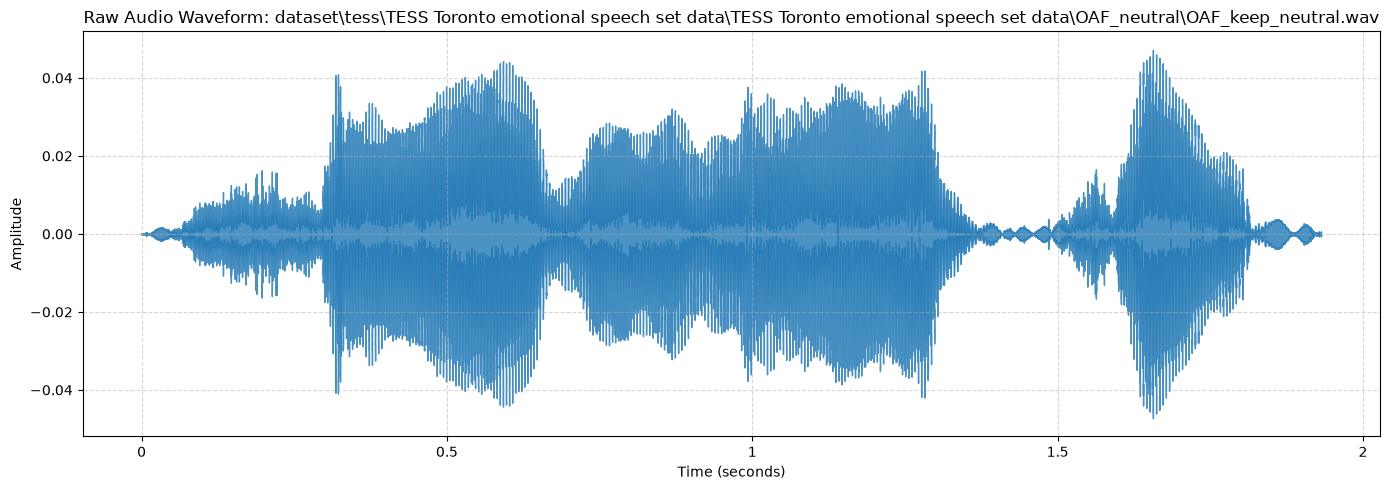

In [113]:
random_sample = dataset.sample(n=1).iloc[0]
path = random_sample['filepath']
    
# Load audio
data, sampling_rate = librosa.load(path)

# Calculate duration dynamically
duration = librosa.get_duration(y=data, sr=sampling_rate)

# Display array dimensions and audio metadata
print(f"Sample Rate (sr): {sampling_rate} Hz")
print(f"Audio Duration: {duration:.2f} seconds")
print(f"Data Array Shape: {data.shape}")
print(f"Expected Data Points ({sampling_rate} * {duration:.2f}): {len(data)}\n")

# Plot the 2D waveform
plt.figure(figsize=(14, 5))
plt.title(f'Raw Audio Waveform: {path.split("/")[-1]}')
librosa.display.waveshow(data, sr=sampling_rate, color='#1f77b4', alpha=0.8)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Generate an inline audio player to listen to the loaded sample
display(Audio(data, rate=sampling_rate))

#### Sampling Rate & Resampling Dynamics

Audio signals are discretized at a set sampling rate ($sr$). In speech recognition tasks, downsampling (e.g., from native 48kHz or 44.1kHz to 22.050kHz or 16kHz) is common to standardize array lengths and reduce computational complexity while retaining essential vocal frequencies.

The code below compares the raw signal loaded at the default rate (22.050 kHz) versus a downsampled rate (16 kHz) to show the effect on array length and memory size.

22.05 kHz Array Length: 55,937 samples | Size: 218.50 KB
16.00 kHz Array Length: 40,590 samples | Size: 158.55 KB
Data Reduction: 27.44% fewer parameters


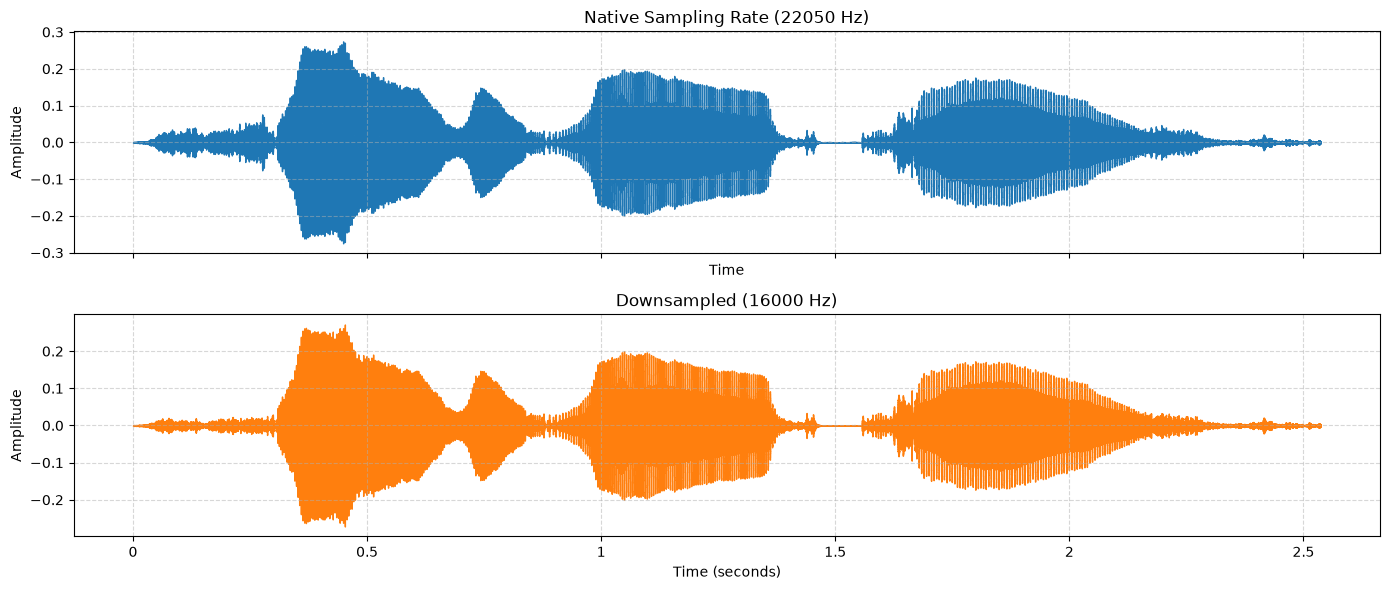

In [105]:
# Compare original vs downsampled rates
sr_default = 22050
sr_downsampled = 16000

y_22k, _ = librosa.load(path, sr=sr_default)
y_16k, _ = librosa.load(path, sr=sr_downsampled)

print(f"22.05 kHz Array Length: {len(y_22k):,} samples | Size: {y_22k.nbytes / 1024:.2f} KB")
print(f"16.00 kHz Array Length: {len(y_16k):,} samples | Size: {y_16k.nbytes / 1024:.2f} KB")
print(f"Data Reduction: {((len(y_22k) - len(y_16k)) / len(y_22k)) * 100:.2f}% fewer parameters")

# Plot side-by-side comparison
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

librosa.display.waveshow(y_22k, sr=sr_default, ax=ax[0], color='#1f77b4')
ax[0].set(title=f'Native Sampling Rate ({sr_default} Hz)', ylabel='Amplitude')
ax[0].grid(True, linestyle='--', alpha=0.5)

librosa.display.waveshow(y_16k, sr=sr_downsampled, ax=ax[1], color='#ff7f0e')
ax[1].set(title=f'Downsampled ({sr_downsampled} Hz)', xlabel='Time (seconds)', ylabel='Amplitude')
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Time vs. Frequency Domain Representation

While waveforms show audio volume over time, emotion recognition relies heavily on spectral information (pitch, harmonic content, and formants). 

* **Short-Time Fourier Transform (STFT):** Converts the 1D signal into a 2D matrix of Frequency (Hz) over Time.
* **Mel-Spectrogram:** Maps frequencies onto the logarithmic Mel Scale, aligning closely with human auditory perception.

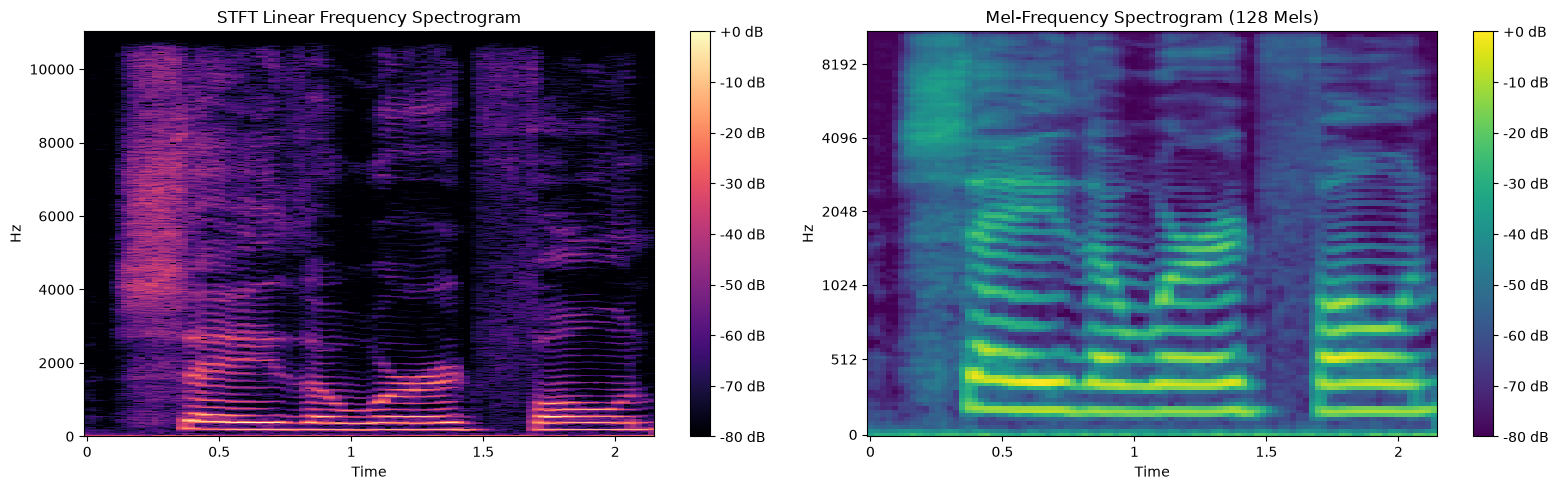

In [108]:
# Compute Short-Time Fourier Transform (STFT)
D = librosa.stft(data)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# Compute Mel-Spectrogram
mel_spec = librosa.feature.melspectrogram(y=data, sr=sampling_rate, n_mels=128)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

# Plot Spectrograms
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Standard Spectrogram
img1 = librosa.display.specshow(S_db, sr=sampling_rate, x_axis='time', y_axis='hz', ax=ax[0], cmap='magma')
fig.colorbar(img1, ax=ax[0], format="%+2.0f dB")
ax[0].set_title('STFT Linear Frequency Spectrogram')

# Mel-Spectrogram
img2 = librosa.display.specshow(mel_spec_db, sr=sampling_rate, x_axis='time', y_axis='mel', ax=ax[1], cmap='viridis')
fig.colorbar(img2, ax=ax[1], format="%+2.0f dB")
ax[1].set_title('Mel-Frequency Spectrogram (128 Mels)')

plt.tight_layout()
plt.show()

#### Comparative Analysis Across Emotions

Emotional expressions differ significantly in pitch variations, power dynamics, and tempo. High-arousal emotions (e.g., Angry, Happy) typically show higher RMS energy spikes compared to low-arousal emotions (e.g., Sad, Neutral).

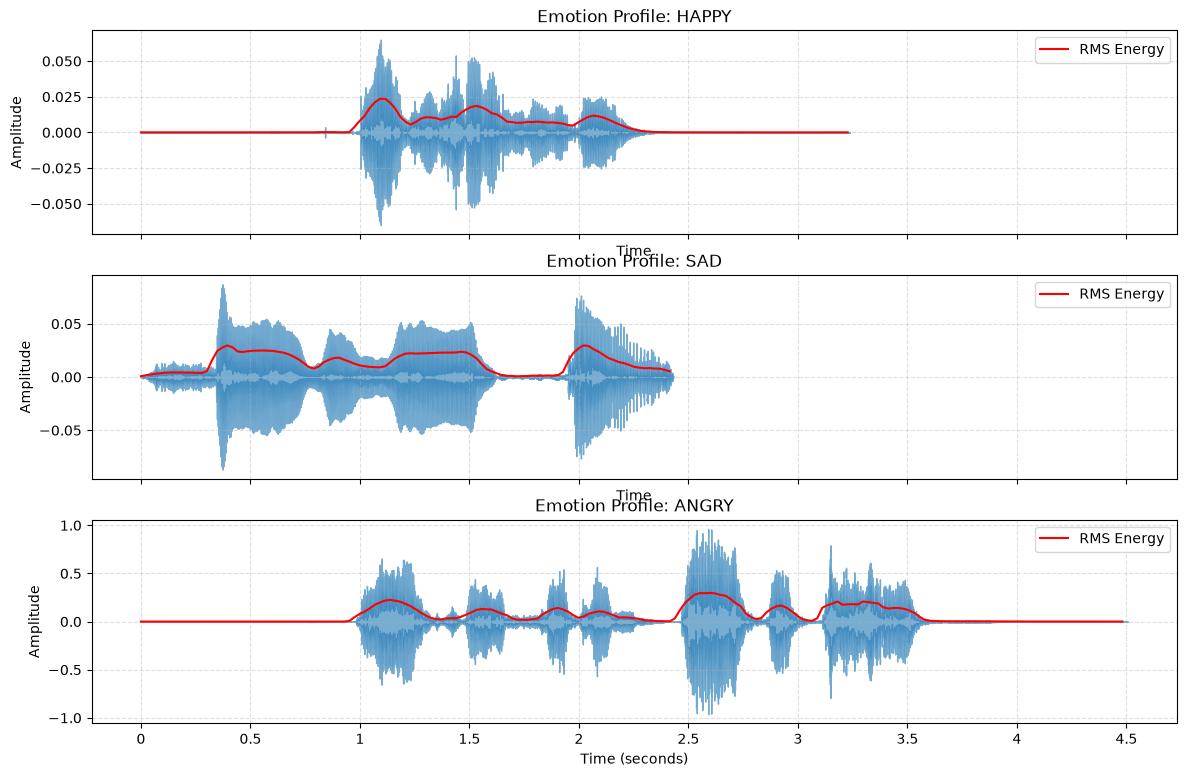

In [ ]:
emotion_samples = {
    'Happy': dataset[dataset['emotion'] == 'happy'].sample(n=1).iloc[0]['filepath'],
    'Sad': dataset[dataset['emotion'] == 'sad'].sample(n=1).iloc[0]['filepath'],
    'Angry': dataset[dataset['emotion'] == 'angry'].sample(n=1).iloc[0]['filepath']
}

fig, axes = plt.subplots(len(emotion_samples), 1, figsize=(14, 3 * len(emotion_samples)), sharex=True)

for ax, (emotion, path) in zip(axes, emotion_samples.items()):
    y_emo, _ = librosa.load(path, sr=22050)
    rms = librosa.feature.rms(y=y_emo)[0]
    frames = range(len(rms))
    times = librosa.frames_to_time(frames, sr=22050)
    
    librosa.display.waveshow(y_emo, sr=22050, ax=ax, alpha=0.6)
    ax.plot(times, rms, color='r', label='RMS Energy')
    ax.set_title(f'Emotion Profile: {emotion.upper()}')
    ax.set_ylabel('Amplitude')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.4)

plt.xlabel('Time (seconds)')
plt.tight_layout()
plt.show()

### Dataset Distributions & Class Balance

Before training, we must confirm that audio lengths are relatively uniform (or determine necessary padding/truncation lengths) and verify that emotion labels are evenly distributed across actors and genders.

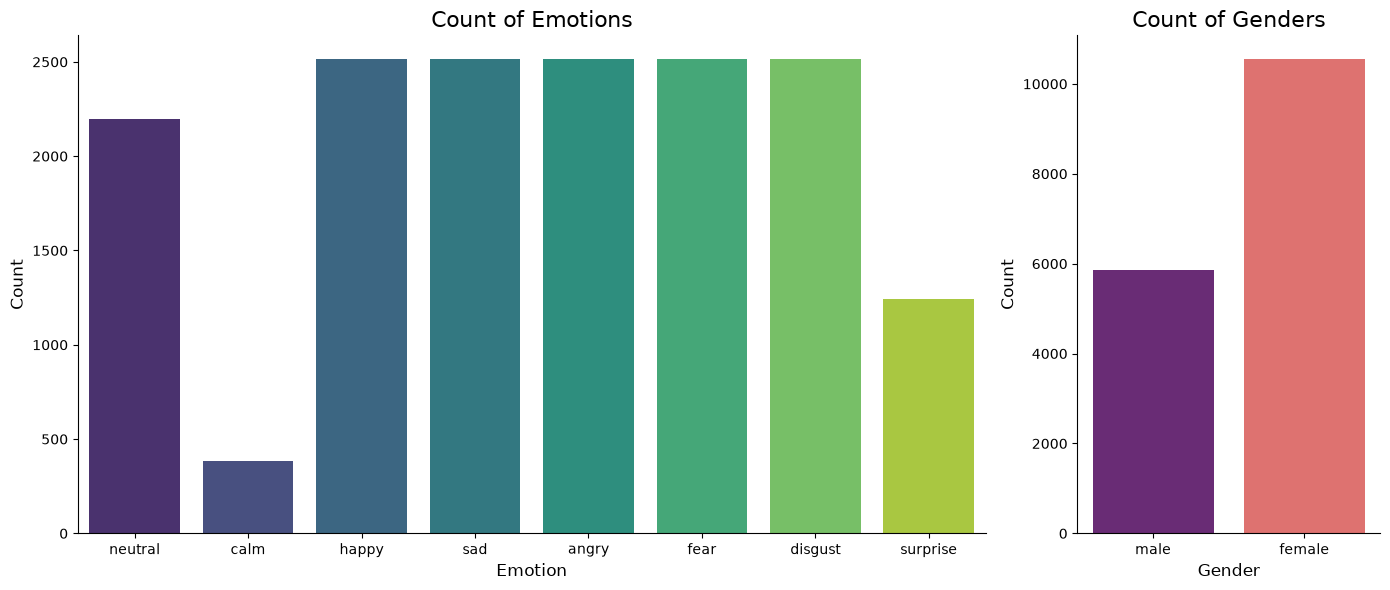

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [3, 1]})

axes[0].set_title('Count of Emotions', size=16)
sns.countplot(x='emotion', data=dataset, hue='emotion', palette='viridis', legend=False, ax=axes[0])
axes[0].set_ylabel('Count', size=12)
axes[0].set_xlabel('Emotion', size=12)
sns.despine(ax=axes[0], top=True, right=True, left=False, bottom=False)

axes[1].set_title('Count of Genders', size=16)
sns.countplot(x='sex', data=dataset, hue='sex', palette='magma', legend=False, ax=axes[1])
axes[1].set_ylabel('Count', size=12) # You can remove this line if you don't want the Y-axis label repeated
axes[1].set_xlabel('Gender', size=12)
sns.despine(ax=axes[1], top=True, right=True, left=False, bottom=False)

plt.tight_layout()
plt.show()

### Audio Visualization by Emotion

**Waveplot**: A waveplot displays the amplitude of an audio signal over time, revealing the physical energy, rhythm, and pauses of the speech.

**Spectrogram**: A spectrogram visualizes the acoustic frequencies of that signal over time, using color intensity to reveal the distinct pitch contours and harmonics that characterize different human emotions.


------------------------------------------------------------
Emotion: NEUTRAL | Source: CREMAD | Gender: Female
------------------------------------------------------------


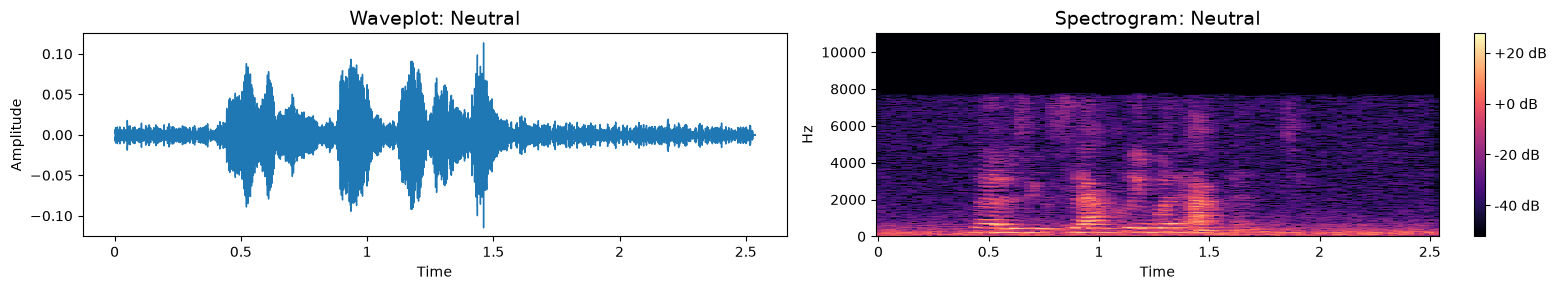


------------------------------------------------------------
Emotion: CALM | Source: RAVDESS | Gender: Female
------------------------------------------------------------


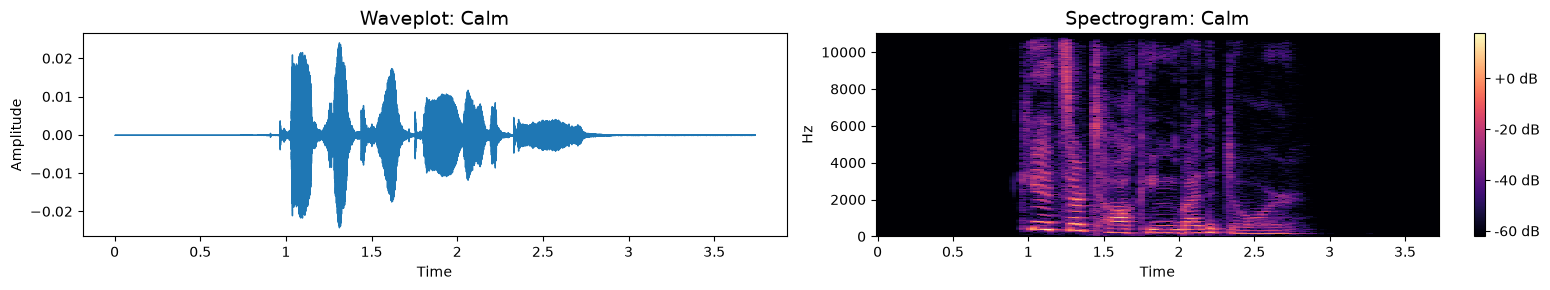


------------------------------------------------------------
Emotion: HAPPY | Source: TESS | Gender: Female
------------------------------------------------------------


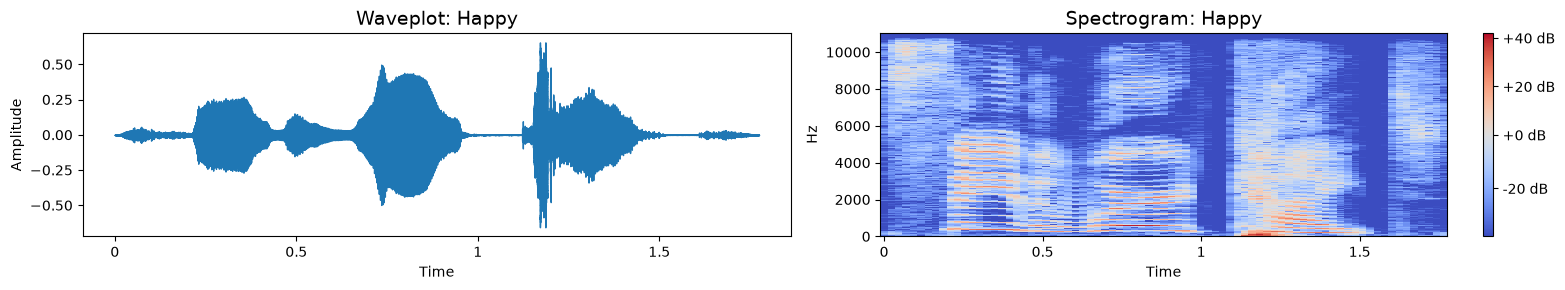


------------------------------------------------------------
Emotion: SAD | Source: CREMAD | Gender: Male
------------------------------------------------------------


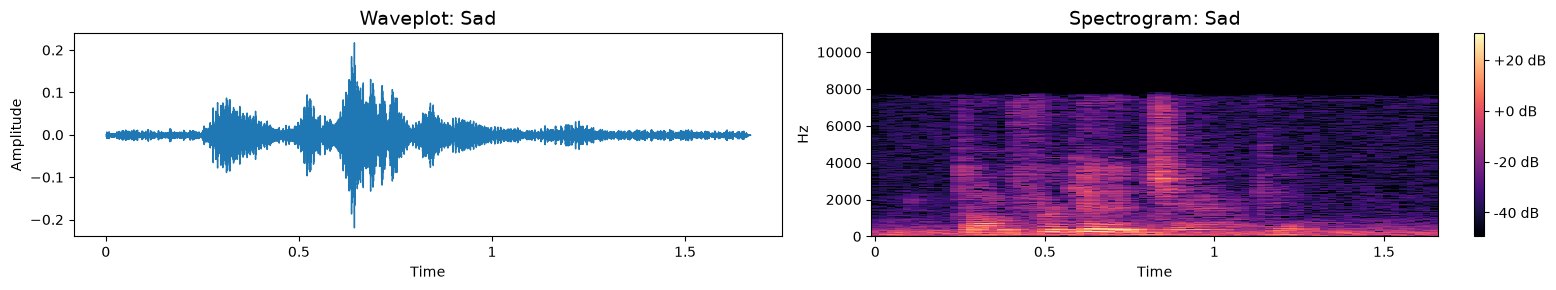


------------------------------------------------------------
Emotion: ANGRY | Source: RAVDESS | Gender: Male
------------------------------------------------------------


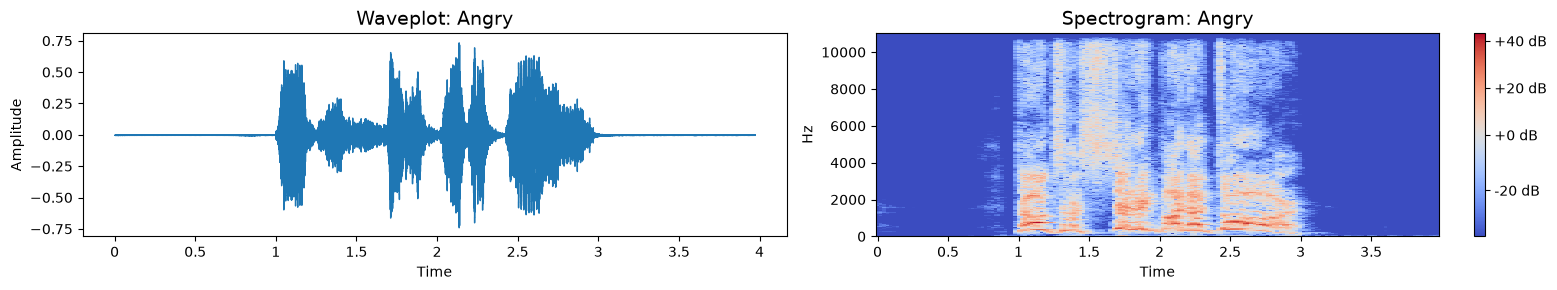


------------------------------------------------------------
Emotion: FEAR | Source: CREMAD | Gender: Female
------------------------------------------------------------


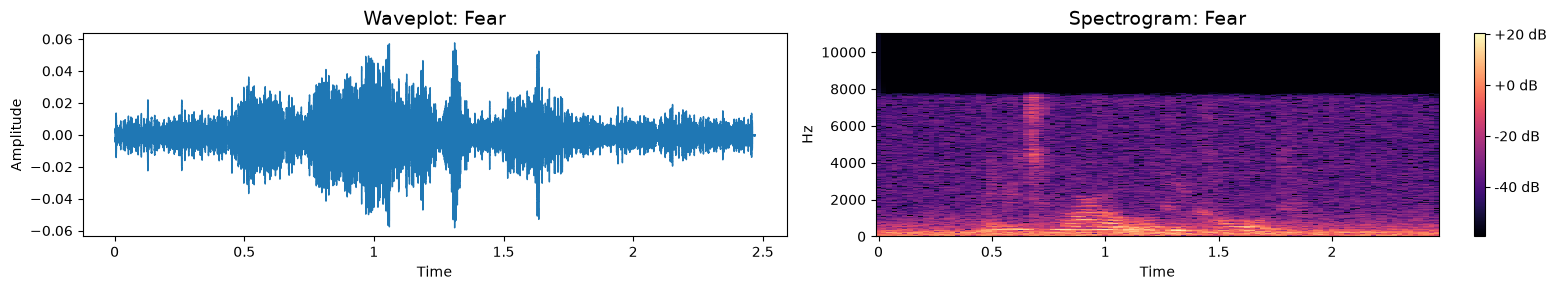


------------------------------------------------------------
Emotion: DISGUST | Source: TESS | Gender: Female
------------------------------------------------------------


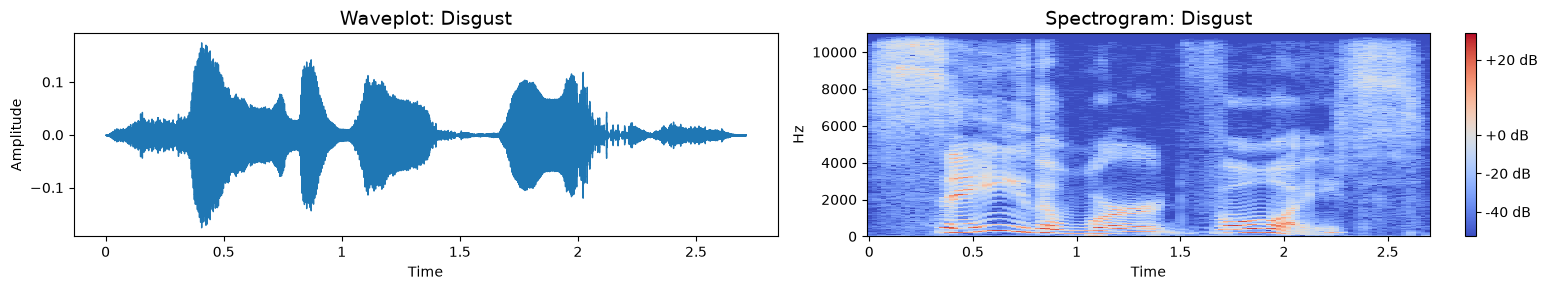


------------------------------------------------------------
Emotion: SURPRISE | Source: TESS | Gender: Female
------------------------------------------------------------


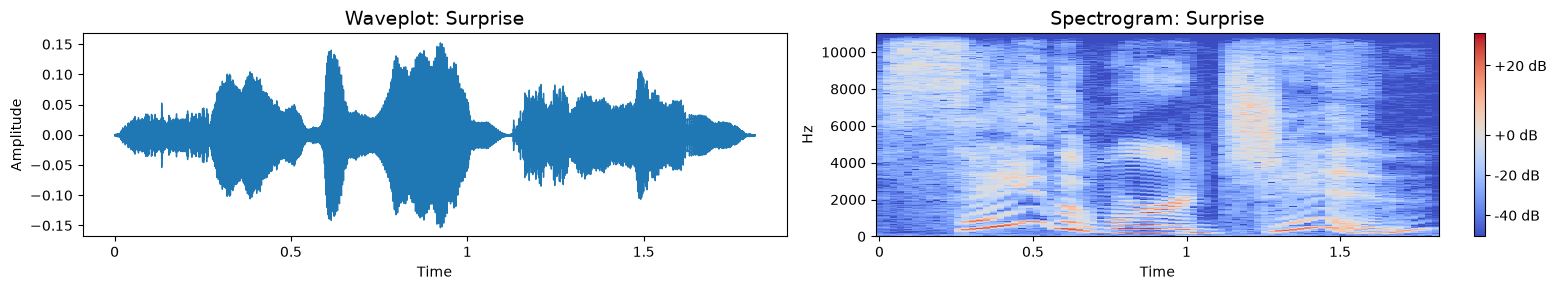

In [111]:
def create_waveplot(data, sr, e):
    plt.figure(figsize=(10, 3))
    plt.title(f'Waveplot for audio with {e} emotion', size=15)
    librosa.display.waveshow(data, sr=sr)
    plt.show()

def create_spectrogram(data, sr, e):
    X = librosa.stft(data)
    Xdb = librosa.amplitude_to_db(abs(X))
    plt.figure(figsize=(12, 3))
    plt.title(f'Spectrogram for audio with {e} emotion', size=15)
    librosa.display.specshow(Xdb, sr=sr, x_axis='time', y_axis='hz')   
    plt.colorbar()
    plt.show()

# Get unique emotions
emotions = dataset['emotion'].dropna().unique()

for emotion in emotions[:8]:
    # Randomly sample one file for the current emotion
    random_sample = dataset[dataset['emotion'] == emotion].sample(n=1).iloc[0]
    path = random_sample['filepath']
    
    # Load audio
    data, sampling_rate = librosa.load(path)
    
    print(f"\n{'-'*60}\nEmotion: {emotion.upper()} | Source: {random_sample['source'].upper()} | Gender: {random_sample['sex'].title()}\n{'-'*60}")
    
    # Create a 1x2 subplot grid for side-by-side waveplot and spectrogram
    fig, axes = plt.subplots(1, 2, figsize=(16, 3))
    
    # --- Plot Waveplot (Left) ---
    librosa.display.waveshow(data, sr=sampling_rate, ax=axes[0])
    axes[0].set_title(f'Waveplot: {emotion.title()}', size=14)
    axes[0].set_xlabel('Time')
    axes[0].set_ylabel('Amplitude')
    
    # --- Plot Spectrogram (Right) ---
    X = librosa.stft(data)
    Xdb = librosa.amplitude_to_db(abs(X))
    img = librosa.display.specshow(Xdb, sr=sampling_rate, x_axis='time', y_axis='hz', ax=axes[1])
    axes[1].set_title(f'Spectrogram: {emotion.title()}', size=14)
    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('Hz')
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")
    
    plt.tight_layout()
    plt.show()
    
    # Render the interactive audio player below the plots
    display(Audio(path))

## Data Augmentation

In [45]:
# Adds random background static scaled to the audio's maximum volume to help the model generalize and ignore minor background interference.
def noise(data):
    noise_amp = 0.035 * np.random.uniform() * np.amax(data)
    data = data + noise_amp * np.random.normal(size=data.shape[0])
    return data

# Alters the speed of the speech (slowing it down in this case with a rate of 0.8) without affecting its natural pitch.
def stretch(data, rate1=0.8):
    return librosa.effects.time_stretch(y=data, rate=rate1)

# Rolls the audio signal forward or backward along the time axis, simulating the speaker starting slightly earlier or later in the recording.
def shift(data):
    shift_range = int(np.random.uniform(low=-5, high=5) * 1000)
    return np.roll(data, shift_range)

# Raises or lowers the tonal frequency of the voice without changing the overall speed or duration of the speech.
def pitch(data, sampling_rate, n_steps=0.7):
    return librosa.effects.pitch_shift(y=data, sr=sampling_rate, n_steps=n_steps)

# Example usage of the augmentation functions
path = dataset['filepath'].iloc[1]
data, sample_rate = librosa.load(path)

augmented_data_noise = noise(data)
Audio(augmented_data_noise, rate=sample_rate)

## Feature Extraction
- **ZCR (Zero-Crossing Rate)**: Measures the rate at which the audio signal changes from positive to negative. This is highly effective for distinguishing between voiced speech (vowels) and unvoiced, noisy sounds (fricative consonants like 's' or 'f').

- **Chroma STFT**: Maps the acoustic energy into 12 distinct pitch classes (the standard musical octave). It captures the underlying harmonic and melodic tone of the voice, which naturally shifts depending on the speaker's emotional state.

- **MFCC (Mel-Frequency Cepstral Coefficients)**: Models the acoustic resonance of the human vocal tract. As the most crucial feature for speech tasks, it maps frequencies to the Mel scale to mathematically mimic human hearing perception.

- **Root Mean Square (RMS) Value**: Calculates the average physical amplitude and power of the audio track over time. This provides a direct measurement of the speaker's loudness and energetic intensity, which helps distinguish angry shouting from calm speaking.

- **MelSpectrogram**: Computes a spectrogram where the frequency bands are spaced according to the human-centric Mel scale. It retains a denser spectral texture than MFCCs, capturing the overarching acoustic envelope and frequency distribution of the emotion.

In [49]:
def extract_features(data):
    # ZCR
    result = np.array([])
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=data).T, axis=0)
    result=np.hstack((result, zcr)) # stacking horizontally

    # Chroma_stft
    stft = np.abs(librosa.stft(data))
    chroma_stft = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
    result = np.hstack((result, chroma_stft)) # stacking horizontally

    # MFCC
    mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mfcc)) # stacking horizontally

    # Root Mean Square Value
    rms = np.mean(librosa.feature.rms(y=data).T, axis=0)
    result = np.hstack((result, rms)) # stacking horizontally

    # MelSpectogram
    mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mel)) # stacking horizontally
    
    return result

## Feature Engineering

In [115]:
# Suppress the FutureWarnings and RuntimeWarnings from librosa/numba
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

def get_features(path):
    # duration and offset handle potential silence at the start/end of audio files
    data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)
    
    # Bundle original and all augmented features cleanly into a single array
    return np.array([
        extract_features(data),
        extract_features(noise(data)),
        extract_features(stretch(data)),
        extract_features(shift(data)),
        extract_features(pitch(data, sample_rate)) # Requires sample_rate passed as an argument
    ])

# 1. Extract and Aggregate Features
def process_file(args):
    path, emotion = args
    features = get_features(path)
    labels = [emotion] * len(features)
    return features, labels

# Bundle paths and emotions into a list of tuples
file_data = list(zip(dataset['filepath'], dataset['emotion']))
X, Y = [], []

# Process multiple files simultaneously across CPU threads
print("Extracting features...")

# CHANGE: ProcessPoolExecutor replaced with ThreadPoolExecutor
with concurrent.futures.ThreadPoolExecutor() as executor:
    # executor.map handles the parallelization automatically
    results = list(tqdm(executor.map(process_file, file_data), total=len(file_data)))

# Unpack the parallelized results back into your main lists
for features, labels in results:
    X.extend(features)
    Y.extend(labels)

X = np.array(X)
Y = np.array(Y)
print("Extraction complete!")

print(f"Feature matrix shape: {X.shape}, Labels shape: {Y.shape}")
print("Starting data preprocessing...")

# 2. Encode Labels
encoder = OneHotEncoder(sparse_output=False) 
Y_encoded = encoder.fit_transform(Y.reshape(-1, 1))

print(f"Encoded labels shape: {Y_encoded.shape}")

# 3. Split Data
x_train, x_test, y_train, y_test = train_test_split(X, Y_encoded, random_state=0, shuffle=True)

# 4. Scale Features
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# 5. Reshape for Conv1D Compatibility
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print(f"Train shape: {x_train.shape}, {y_train.shape}")
print(f"Test shape:  {x_test.shape}, {y_test.shape}")

Extracting features...


 89%|████████▉ | 14633/16402 [19:20<02:52, 10.27it/s]c:\Users\lucas\miniconda3\envs\ser\Lib\site-packages\librosa\core\pitch.py:105: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
100%|██████████| 16402/16402 [21:14<00:00, 12.87it/s]


Extraction complete!
Feature matrix shape: (82010, 162), Labels shape: (82010,)
Starting data preprocessing...
Encoded labels shape: (82010, 8)
Train shape: (61507, 162, 1), (61507, 8)
Test shape:  (20503, 162, 1), (20503, 8)


## Model One: Random Forest
A Random Forest is a robust ensemble learning algorithm that operates by constructing a multitude of independent decision trees during training and outputting the mode (majority vote) of the classes for predictions. In this project, it serves as our foundational baseline classifier. Because it natively processes flat, tabular arrays, we fed our scaled, 2D acoustic feature vectors (combining ZCR, MFCCs, and MelSpectrogram data) directly into the algorithm without the multidimensional tensor reshaping required by our deep learning models. We utilized GridSearchCV to optimize the forest's hyper-architecture—tuning the overall number of trees (n_estimators) and their maximum depth—to ensure peak performance. By aggregating the decisions of hundreds of uncorrelated trees, the Random Forest naturally mitigates overfitting and untangles complex, non-linear audio relationships.

Starting GridSearchCV for Random Forest...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best parameters found: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}


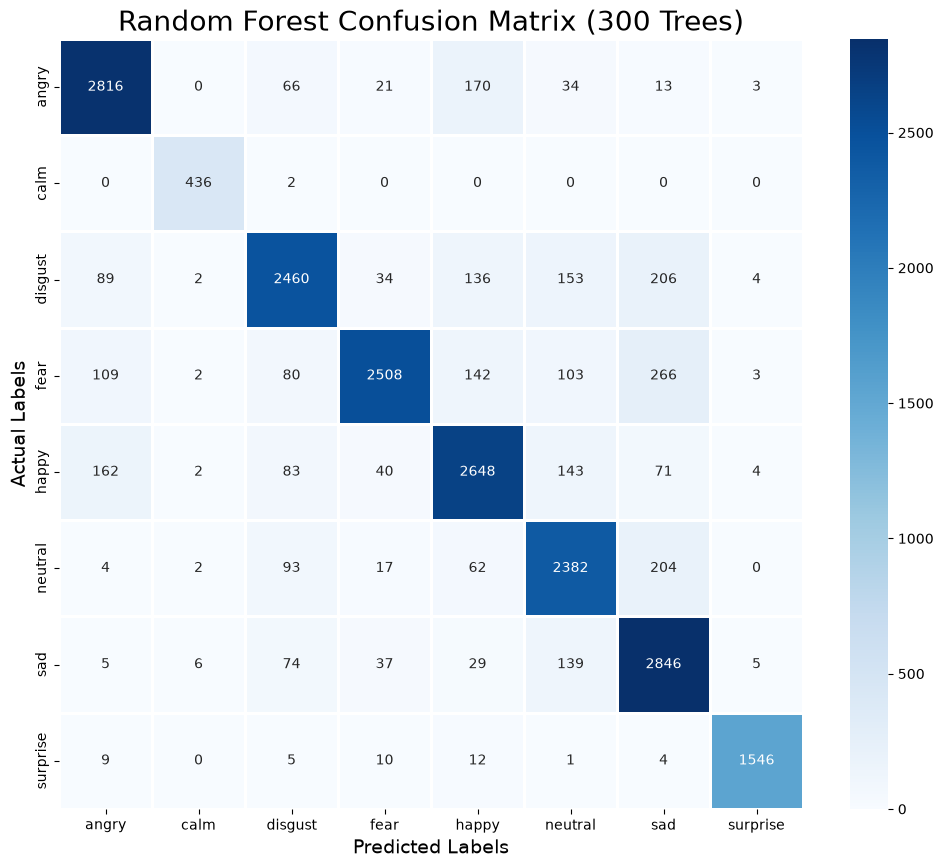

Random Forest Accuracy: 86.05%

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

       angry       0.88      0.90      0.89      3123
        calm       0.97      1.00      0.98       438
     disgust       0.86      0.80      0.83      3084
        fear       0.94      0.78      0.85      3213
       happy       0.83      0.84      0.83      3153
     neutral       0.81      0.86      0.83      2764
         sad       0.79      0.91      0.84      3141
    surprise       0.99      0.97      0.98      1587

    accuracy                           0.86     20503
   macro avg       0.88      0.88      0.88     20503
weighted avg       0.86      0.86      0.86     20503



['saved_models/best_rf_model.joblib']

In [122]:
# Preprocessing
x_train_rf, x_test_rf, y_train_rf, y_test_rf = train_test_split(X, Y, random_state=0, shuffle=True)

scaler_rf = StandardScaler()
x_train_rf = scaler_rf.fit_transform(x_train_rf)
x_test_rf = scaler_rf.transform(x_test_rf)

# Hyperparameter Tuning using GridSearchCV
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

print("Starting GridSearchCV for Random Forest...")
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=0), 
    param_grid_rf, 
    refit=True, 
    verbose=3, 
    cv=5, 
    n_jobs=16
    )
grid_rf.fit(x_train_rf, y_train_rf)

print(f"\nBest parameters found: {grid_rf.best_params_}")

# Generate Predictions with the Best Model
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(x_test_rf)

# Retrieve the unique string categories directly from the raw labels for plotting
categories_rf = np.unique(Y)


# Confusion Matrix Heatmap
cm_rf = confusion_matrix(y_test_rf, y_pred_rf, labels=categories_rf)
plt.figure(figsize=(12, 10))
cm_rf_df = pd.DataFrame(cm_rf, index=categories_rf, columns=categories_rf)

# fmt='d' ensures integer formatting
sns.heatmap(cm_rf_df, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='d')
plt.title(f'Random Forest Confusion Matrix ({grid_rf.best_params_["n_estimators"]} Trees)', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.show()

# Classification Report
print(f"Random Forest Accuracy: {accuracy_score(y_test_rf, y_pred_rf) * 100:.2f}%\n")
print("--- Random Forest Classification Report ---")
print(classification_report(y_test_rf, y_pred_rf, target_names=categories_rf))

import json
import joblib

# Save the best hyperparameters as a readable JSON
with open('saved_models/rf_params.json', 'w') as f:
    json.dump(grid_rf.best_params_, f, indent=4)

# Save the actual trained Scikit-Learn model object
joblib.dump(grid_rf.best_estimator_, 'saved_models/best_rf_model.joblib')

## Model Two: SVM
A Support Vector Machine (SVM) is a classical machine learning algorithm that classifies data by finding an optimal mathematical hyperplane that separates categories with the maximum possible margin. In this project, it serves as a robust baseline to benchmark against our deep learning architectures. After reshaping our extracted acoustic feature tensors (such as MFCCs and ZCR) into standard 2D arrays, we process them through the SVM using GridSearchCV to exhaustively optimize hyperparameters. By leveraging the Radial Basis Function (RBF) kernel, the algorithm projects our highly non-linear audio data into a higher-dimensional space to cleanly map boundaries between the eight distinct emotion classes. 

In [ ]:
# Adapt deep learning shapes for Scikit-Learn SVM
x_train_svm = np.squeeze(x_train, axis=-1)
x_test_svm = np.squeeze(x_test, axis=-1)

y_train_svm = np.argmax(y_train, axis=1)
y_test_svm = np.argmax(y_test, axis=1)

# Hyperparameter Tuning using GridSearchCV
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'poly', 'sigmoid']
}

print("Starting GridSearchCV for SVM...")
grid = GridSearchCV(
    SVC(), 
    param_grid, 
    refit=True, 
    verbose=3, 
    cv=5, 
    n_jobs=2
    )
grid.fit(x_train_svm, y_train_svm)

print(f"\nBest parameters found: {grid.best_params_}")

# Generate Predictions with the Best Model
best_svm = grid.best_estimator_
y_pred_svm_indices = best_svm.predict(x_test_svm)

# Map integer indices back to original string emotion labels
categories_emo = encoder.categories_[0]
y_pred_labels_svm = categories_emo[y_pred_svm_indices]
y_test_labels_svm = categories_emo[y_test_svm]

import json
import joblib

# Save the best hyperparameters as a readable JSON
with open('saved_models/svm_params.json', 'w') as f:
    json.dump(grid.best_params_, f, indent=4)

# Save the actual trained Scikit-Learn model object
joblib.dump(grid.best_estimator_, 'saved_models/best_svm_model.joblib')

In [ ]:
# DataFrame Preview
df_svm = pd.DataFrame({
    'Predicted Labels': y_pred_labels_svm, 
    'Actual Labels': y_test_labels_svm
})
display(df_svm.head(10))

# Confusion Matrix Heatmap
cm_svm = confusion_matrix(y_test_labels_svm, y_pred_labels_svm, labels=categories_emo)
plt.figure(figsize=(12, 10))
cm_svm_df = pd.DataFrame(cm_svm, index=categories_emo, columns=categories_emo)

# fmt='d' ensures integer formatting
sns.heatmap(cm_svm_df, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='d')
plt.title(f'SVM Confusion Matrix (Kernel: {grid.best_params_["kernel"]})', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.show()

# Classification Report
print(f"SVM Accuracy: {accuracy_score(y_test_labels_svm, y_pred_labels_svm) * 100:.2f}%\n")
print("--- SVM Classification Report ---")
print(classification_report(y_test_labels_svm, y_pred_labels_svm, target_names=categories_emo))

## Model Three: CNN
1D Convolutional Neural Network designed to process sequential audio features by sliding numerical filters across your extracted data. It utilizes four consecutive blocks of 1D convolutions, ReLU activations, and max-pooling to progressively identify and downsample complex temporal patterns from the raw ZCR, MFCC, and MelSpectrogram vectors. After flattening these high-level feature maps, the network passes the data through fully connected dense layers with dropout regularization to map those localized acoustic patterns into probabilities across the eight distinct emotion categories.


In [64]:

class OneDCNN(nn.Module):
    def __init__(self, input_dim, num_classes=8):
        super(OneDCNN, self).__init__()
        
        # Block 1: Conv1D -> ReLU -> MaxPool1D
        self.block1 = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=256, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=5, stride=2, padding=2)
        )
        
        # Block 2: Conv1D -> ReLU -> MaxPool1D
        self.block2 = nn.Sequential(
            nn.Conv1d(in_channels=256, out_channels=256, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=5, stride=2, padding=2)
        )
        
        # Block 3: Conv1D -> ReLU -> MaxPool1D -> Dropout
        self.block3 = nn.Sequential(
            nn.Conv1d(in_channels=256, out_channels=128, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=5, stride=2, padding=2),
            nn.Dropout(0.2)
        )
        
        # Block 4: Conv1D -> ReLU -> MaxPool1D
        self.block4 = nn.Sequential(
            nn.Conv1d(in_channels=128, out_channels=64, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=5, stride=2, padding=2)
        )
        
        # Dynamically calculate the flattened feature size after 4 max-pooling layers
        # Each MaxPool1d with kernel_size=5, stride=2, padding=2 halves the sequence length roughly: L -> L/2 -> L/4 -> L/8 -> L/16
        dummy_input = torch.zeros(1, 1, input_dim)
        with torch.no_grad():
            x = self.block1(dummy_input)
            x = self.block2(x)
            x = self.block3(x)
            x = self.block4(x)
            flatten_size = x.numel()
            
        # Fully Connected Classifier Layers
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flatten_size, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        if x.shape[-1] == 1:
            x = x.permute(0, 2, 1)
            
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.fc_layers(x)
        return x


### Training

In [65]:
# Convert NumPy arrays to PyTorch Tensors
x_train_tensor = torch.tensor(x_train, dtype=torch.float32).to(device)
y_train_indices = torch.tensor(np.argmax(y_train, axis=1), dtype=torch.long).to(device)

x_test_tensor = torch.tensor(x_test, dtype=torch.float32).to(device)
y_test_indices = torch.tensor(np.argmax(y_test, axis=1), dtype=torch.long).to(device)

# Create DataLoaders to handle the batch_size=64 requirement
train_dataset = TensorDataset(x_train_tensor, y_train_indices)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

test_dataset = TensorDataset(x_test_tensor, y_test_indices)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Instantiate model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = OneDCNN(input_dim=x_train.shape[1], num_classes=8).to(device)

# Define Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

# Define Learning Rate Scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode='min', 
    factor=0.4, 
    patience=2, 
    min_lr=0.0000001
)

# Dictionary to replicate the Keras 'history.history' object
history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

# Training Loop
epochs = 50
for epoch in range(epochs):
    # --- Training Phase ---
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = correct_train / total_train
    
    # --- Validation Phase ---
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = val_loss / len(test_dataset)
    epoch_val_acc = correct_val / total_val
    
    # Step the scheduler based on training loss
    scheduler.step(epoch_train_loss)
    
    # Store metrics for your graphs
    history['loss'].append(epoch_train_loss)
    history['accuracy'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_accuracy'].append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{epochs}] - "
          f"loss: {epoch_train_loss:.4f} - accuracy: {epoch_train_acc:.4f} - "
          f"val_loss: {epoch_val_loss:.4f} - val_accuracy: {epoch_val_acc:.4f}")

# Final Evaluation
print(f"Accuracy of our model on test data : {history['val_accuracy'][-1] * 100:.2f} %")

Epoch [1/50] - loss: 1.4636 - accuracy: 0.4202 - val_loss: 1.1899 - val_accuracy: 0.5249
Epoch [2/50] - loss: 1.1930 - accuracy: 0.5267 - val_loss: 1.0469 - val_accuracy: 0.5860
Epoch [3/50] - loss: 1.1206 - accuracy: 0.5553 - val_loss: 1.0352 - val_accuracy: 0.5879
Epoch [4/50] - loss: 1.0750 - accuracy: 0.5720 - val_loss: 0.9868 - val_accuracy: 0.6105
Epoch [5/50] - loss: 1.0435 - accuracy: 0.5838 - val_loss: 0.9640 - val_accuracy: 0.6196
Epoch [6/50] - loss: 1.0113 - accuracy: 0.5967 - val_loss: 0.9277 - val_accuracy: 0.6332
Epoch [7/50] - loss: 0.9945 - accuracy: 0.6034 - val_loss: 0.9260 - val_accuracy: 0.6311
Epoch [8/50] - loss: 0.9699 - accuracy: 0.6135 - val_loss: 0.8904 - val_accuracy: 0.6458
Epoch [9/50] - loss: 0.9513 - accuracy: 0.6214 - val_loss: 0.8843 - val_accuracy: 0.6468
Epoch [10/50] - loss: 0.9354 - accuracy: 0.6285 - val_loss: 0.9075 - val_accuracy: 0.6404
Epoch [11/50] - loss: 0.9057 - accuracy: 0.6397 - val_loss: 0.8455 - val_accuracy: 0.6610
Epoch [12/50] - los

### Model Analysis

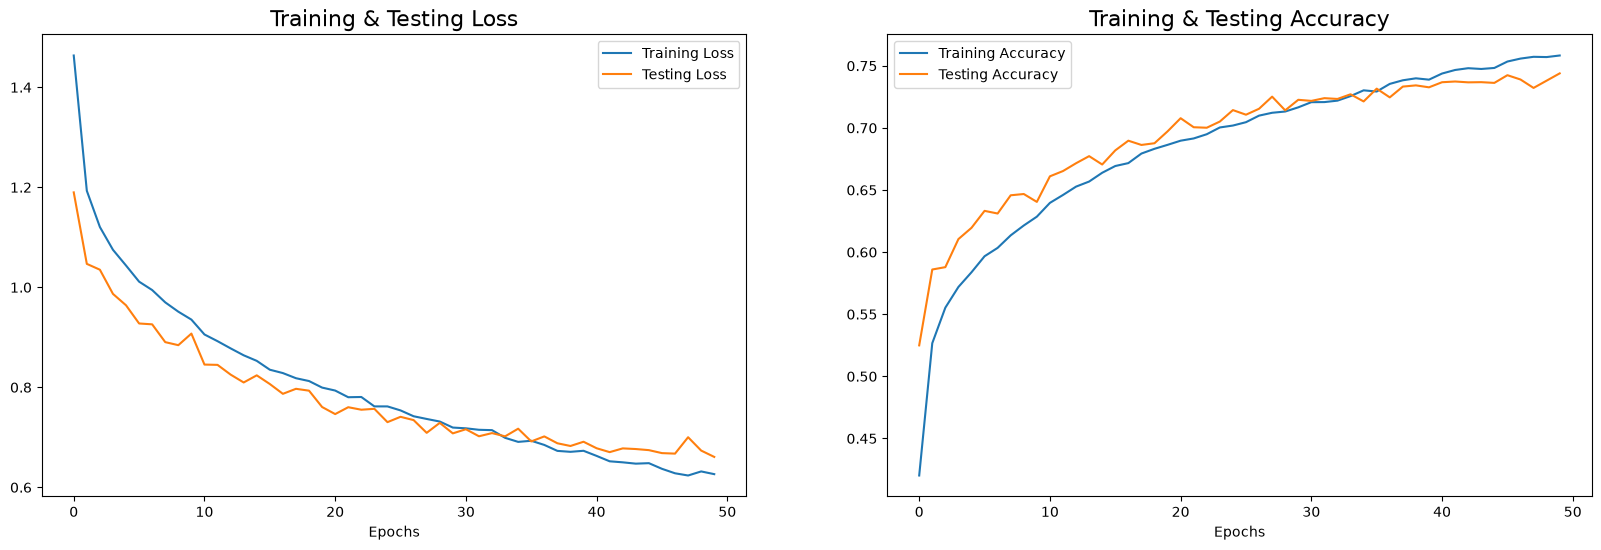

In [66]:
epochs_range = range(epochs)
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# Plot Loss
ax[0].plot(epochs_range, history['loss'], label='Training Loss')
ax[0].plot(epochs_range, history['val_loss'], label='Testing Loss')
ax[0].set_title('Training & Testing Loss', size=16)
ax[0].set_xlabel("Epochs")
ax[0].legend()

# Plot Accuracy
ax[1].plot(epochs_range, history['accuracy'], label='Training Accuracy')
ax[1].plot(epochs_range, history['val_accuracy'], label='Testing Accuracy')
ax[1].set_title('Training & Testing Accuracy', size=16)
ax[1].set_xlabel("Epochs")
ax[1].legend()

plt.show()

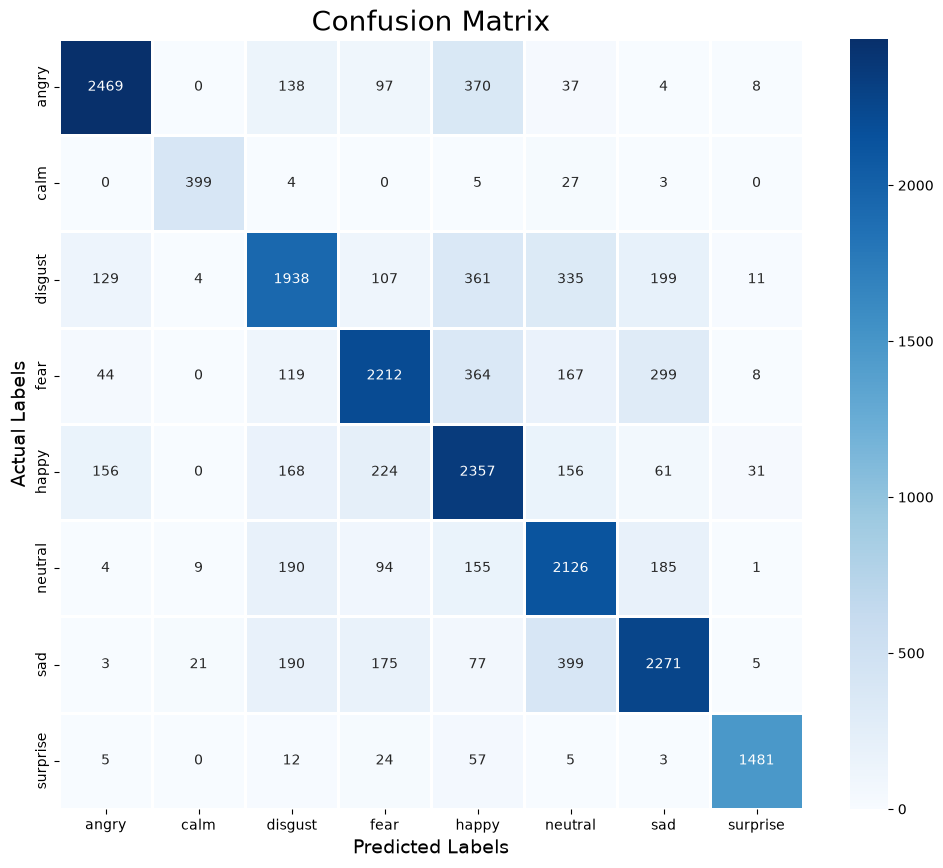

              precision    recall  f1-score   support

       angry       0.88      0.79      0.83      3123
        calm       0.92      0.91      0.92       438
     disgust       0.70      0.63      0.66      3084
        fear       0.75      0.69      0.72      3213
       happy       0.63      0.75      0.68      3153
     neutral       0.65      0.77      0.71      2764
         sad       0.75      0.72      0.74      3141
    surprise       0.96      0.93      0.95      1587

    accuracy                           0.74     20503
   macro avg       0.78      0.77      0.78     20503
weighted avg       0.75      0.74      0.75     20503



In [79]:
# Generate predictions
with torch.no_grad():
    pred_logits = model(x_test_tensor)
    pred_indices = torch.argmax(pred_logits, dim=1).cpu().numpy()

actual_indices = y_test_indices.cpu().numpy()

# Map integer indices back to the original string emotion labels
categories = encoder.categories_[0]
y_pred_labels = categories[pred_indices]
y_test_labels = categories[actual_indices]

# Create and display the DataFrame
df = pd.DataFrame({
    'Predicted Labels': y_pred_labels, 
    'Actual Labels': y_test_labels
})

# Generate the Confusion Matrix
cm = confusion_matrix(y_test_labels, y_pred_labels, labels=categories)

# Plot the Heatmap
plt.figure(figsize=(12, 10))
cm_df = pd.DataFrame(cm, index=categories, columns=categories)
sns.heatmap(cm_df, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='d')
plt.title('Confusion Matrix', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.show()

# Classification Report
print(classification_report(y_test_labels, y_pred_labels, target_names=categories))

## Model Four: Stacked CNN

The StackedCNN is a streamlined 1D Convolutional Neural Network optimized for Speech Emotion Recognition that aggressively groups convolutional layers together to extract deep, overlapping temporal audio patterns before executing a single, massive downsampling step. Inside the class, the \_\_init\_\_ method constructs this architecture by defining the consecutive convolutional blocks, dynamically calculating the flattened tensor dimensions, and building a shallow classification head that maps directly to the eight emotion categories without intermediate dense layers. The forward method orchestrates the data pipeline by first permuting the input arrays to satisfy PyTorch's channel-first dimension requirements, passing the tensor sequentially through the configured blocks, and outputting the final emotion prediction logits.

In [72]:
class StackedCNN(nn.Module):
    def __init__(self, input_dim, num_classes=8):
        super(StackedCNN, self).__init__()
        
        # Block 1: Double Conv1D -> Dropout -> Massive MaxPool
        # padding=2 acts as Keras padding='same' for kernel_size=5
        self.block1 = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=256, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.Conv1d(in_channels=256, out_channels=128, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.MaxPool1d(kernel_size=8, stride=8) # Massive downsampling
        )
        
        # Block 2: Double Conv1D
        self.block2 = nn.Sequential(
            nn.Conv1d(in_channels=128, out_channels=128, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.Conv1d(in_channels=128, out_channels=128, kernel_size=5, stride=1, padding=2),
            nn.ReLU()
        )
        
        # Dynamically calculate the flattened feature size
        dummy_input = torch.zeros(1, 1, input_dim)
        with torch.no_grad():
            x = self.block1(dummy_input)
            x = self.block2(x)
            flatten_size = x.numel()
            
        # Direct Classification Head (No Hidden Dense Layer)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flatten_size, num_classes)
        )

    def forward(self, x):
        # Permute (Batch, Length, Channels) to PyTorch's expected (Batch, Channels, Length)
        if x.shape[-1] == 1:
            x = x.permute(0, 2, 1)
            
        x = self.block1(x)
        x = self.block2(x)
        x = self.classifier(x)
        return x

# Instantiate the StackedCNN model

model_stacked = StackedCNN(input_dim=x_train.shape[1], num_classes=8).to(device)

# 2. Initialize the optimizer and learning rate scheduler
optimizer = optim.Adam(model_stacked.parameters(), lr=1e-4)

scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.98)

criterion = nn.CrossEntropyLoss()

# 3. Set up Early Stopping parameters
patience = 5
patience_counter = 0
best_val_acc = 0.0
best_model_weights = None

history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

# Training Loop
epochs = 50
for epoch in range(epochs):
    # --- Training Phase ---
    model_stacked.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model_stacked(inputs)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = correct_train / total_train
    
    # --- Validation Phase ---
    model_stacked.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model_stacked(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = val_loss / len(test_dataset)
    epoch_val_acc = correct_val / total_val
    
    # Step the learning rate decay scheduler
    scheduler.step()
    
    history['loss'].append(epoch_train_loss)
    history['accuracy'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_accuracy'].append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{epochs}] - loss: {epoch_train_loss:.4f} - acc: {epoch_train_acc:.4f} | val_loss: {epoch_val_loss:.4f} - val_acc: {epoch_val_acc:.4f}")

    # --- Early Stopping Logic (restore_best_weights=True) ---
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_model_weights = copy.deepcopy(model_stacked.state_dict())
        patience_counter = 0 
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"\nEarly stopping triggered at Epoch {epoch+1}! No improvement in validation accuracy for {patience} epochs.")
            break

# Restore the best weights discovered during training
print(f"Restoring best model weights with Validation Accuracy: {best_val_acc * 100:.2f}%")
if best_model_weights is not None:
    model_stacked.load_state_dict(best_model_weights)

Epoch [1/50] - loss: 1.3153 - acc: 0.5089 | val_loss: 1.0921 - val_acc: 0.5879
Epoch [2/50] - loss: 1.0288 - acc: 0.6074 | val_loss: 0.9975 - val_acc: 0.6165
Epoch [3/50] - loss: 0.9448 - acc: 0.6377 | val_loss: 0.9448 - val_acc: 0.6365
Epoch [4/50] - loss: 0.8929 - acc: 0.6578 | val_loss: 0.8800 - val_acc: 0.6627
Epoch [5/50] - loss: 0.8503 - acc: 0.6730 | val_loss: 0.8674 - val_acc: 0.6636
Epoch [6/50] - loss: 0.8181 - acc: 0.6859 | val_loss: 0.8269 - val_acc: 0.6770
Epoch [7/50] - loss: 0.7852 - acc: 0.6978 | val_loss: 0.8070 - val_acc: 0.6922
Epoch [8/50] - loss: 0.7566 - acc: 0.7093 | val_loss: 0.7756 - val_acc: 0.6995
Epoch [9/50] - loss: 0.7314 - acc: 0.7196 | val_loss: 0.7575 - val_acc: 0.7077
Epoch [10/50] - loss: 0.7090 - acc: 0.7277 | val_loss: 0.7402 - val_acc: 0.7184
Epoch [11/50] - loss: 0.6860 - acc: 0.7379 | val_loss: 0.7243 - val_acc: 0.7188
Epoch [12/50] - loss: 0.6675 - acc: 0.7462 | val_loss: 0.7113 - val_acc: 0.7288
Epoch [13/50] - loss: 0.6491 - acc: 0.7533 | val_

### Model Analysis

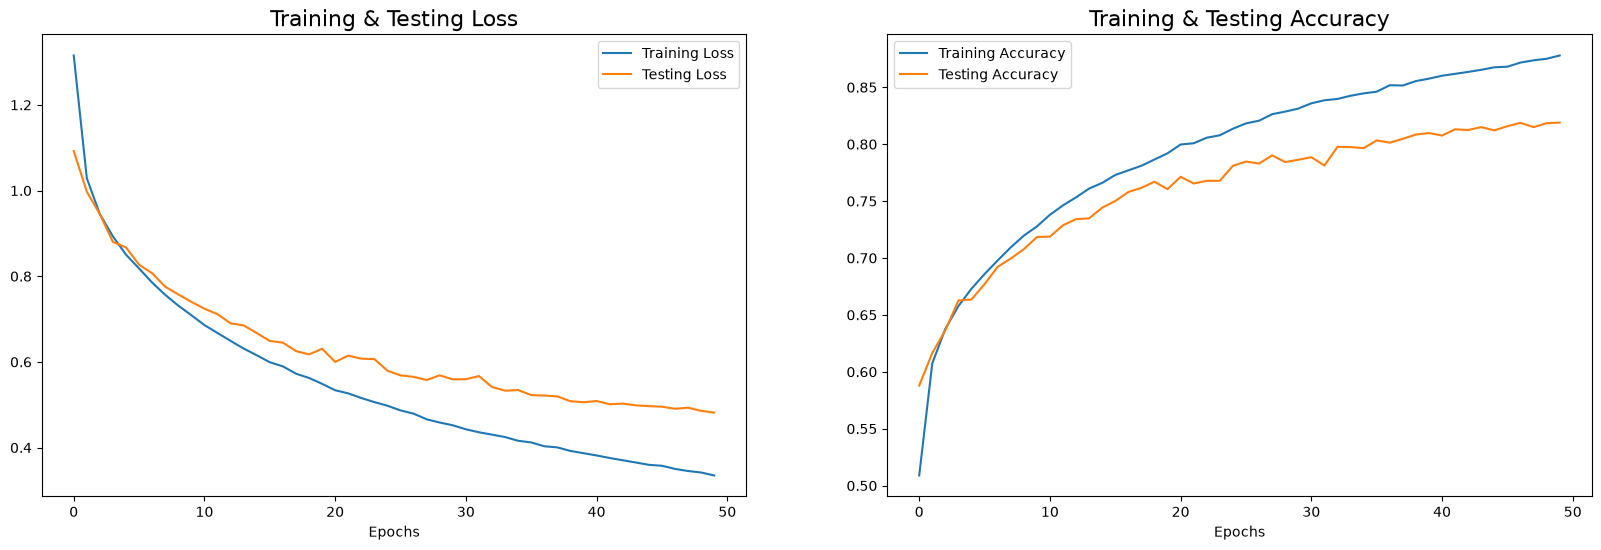

In [76]:
# Dynamically calculate the actual number of epochs trained before early stopping
actual_epochs = len(history['loss'])
epochs_range = range(actual_epochs)

fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# Plot Training & Validation Loss
ax[0].plot(epochs_range, history['loss'], label='Training Loss')
ax[0].plot(epochs_range, history['val_loss'], label='Testing Loss')
ax[0].set_title('Training & Testing Loss', size=16)
ax[0].set_xlabel("Epochs")
ax[0].legend()

# Plot Training & Validation Accuracy
ax[1].plot(epochs_range, history['accuracy'], label='Training Accuracy')
ax[1].plot(epochs_range, history['val_accuracy'], label='Testing Accuracy')
ax[1].set_title('Training & Testing Accuracy', size=16)
ax[1].set_xlabel("Epochs")
ax[1].legend()

plt.show()

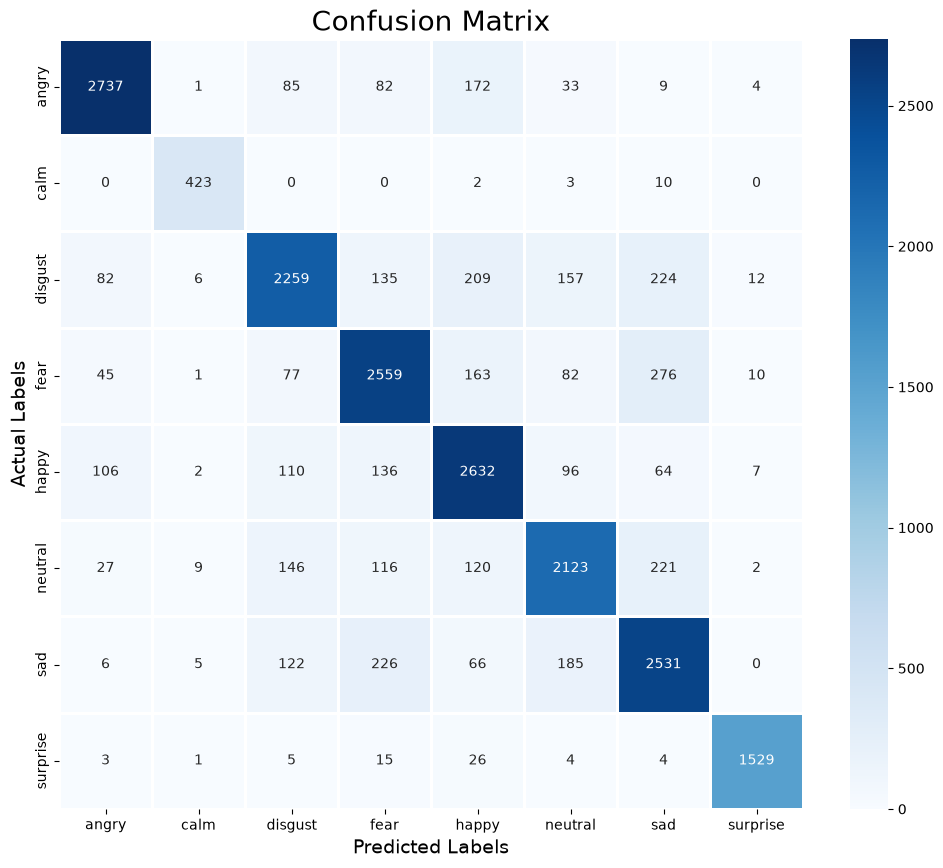

              precision    recall  f1-score   support

       angry       0.91      0.88      0.89      3123
        calm       0.94      0.97      0.95       438
     disgust       0.81      0.73      0.77      3084
        fear       0.78      0.80      0.79      3213
       happy       0.78      0.83      0.80      3153
     neutral       0.79      0.77      0.78      2764
         sad       0.76      0.81      0.78      3141
    surprise       0.98      0.96      0.97      1587

    accuracy                           0.82     20503
   macro avg       0.84      0.84      0.84     20503
weighted avg       0.82      0.82      0.82     20503



In [78]:
import pandas as pd
import torch

# Generate predictions using the StackedCNN PyTorch model
model_stacked.eval()
with torch.no_grad():
    pred_logits = model_stacked(x_test_tensor)
    pred_indices = torch.argmax(pred_logits, dim=1).cpu().numpy()

actual_indices = y_test_indices.cpu().numpy()

# Map integer indices back to the original string emotion labels
categories = encoder.categories_[0]
y_pred_labels = categories[pred_indices]
y_test_labels = categories[actual_indices]

# Create and display the DataFrame
df = pd.DataFrame({
    'Predicted Labels': y_pred_labels, 
    'Actual Labels': y_test_labels
})

# Confusion Matrix
cm = confusion_matrix(y_test_labels, y_pred_labels, labels=categories)

# 2. Plot the Heatmap
plt.figure(figsize=(12, 10))
cm_df = pd.DataFrame(cm, index=categories, columns=categories)

# fmt='d' ensures integer formatting instead of scientific notation
sns.heatmap(cm_df, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='d')
plt.title('Confusion Matrix', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.show()

# 3. Print the Classification Report
print(classification_report(y_test_labels, y_pred_labels, target_names=categories))

## Model Five: Hierarchical Ensemble CNN

Hierarchical Ensemble CNN divides the complex problem of Speech Emotion Recognition into a two-step decision tree. First, a dedicated neural network classifies the speaker's biological sex (male or female), acting as a routing mechanism. Based on that prediction, the audio signal is forwarded to one of two specialized, sex-specific emotion classifiers. This ensemble approach is highly effective because male and female vocal tracts resonate differently; by training isolated models, the network doesn't have to learn a compromised "middle ground" representation, allowing it to focus strictly on the distinct pitch and frequency shifts unique to each sex's emotional expression.

In [91]:
# Define the extraction helper
def process_ensemble_file(args):
    path, emotion, sex = args
    features = get_features(path)
    
    # Duplicate the labels for each augmented array returned
    labels_emo = [emotion] * len(features)
    labels_sex = [sex] * len(features)
    return features, labels_emo, labels_sex

# Bundle the data
file_data = list(zip(dataset.filepath, dataset.emotion, dataset.sex))

X, Y_emotion, Y_sex = [], [], []

# 3. Execute Parallel Extraction
print("Extracting features with ThreadPoolExecutor...")
with concurrent.futures.ThreadPoolExecutor() as executor:
    results = list(tqdm(executor.map(process_ensemble_file, file_data), total=len(file_data)))

# Unpack results
for features, emo_labels, sex_labels in results:
    X.extend(features)
    Y_emotion.extend(emo_labels)
    Y_sex.extend(sex_labels)

# Create and shuffle the missing DataFrame
ensemble_Features = pd.DataFrame(X)
ensemble_Features['labels_emotion'] = Y_emotion
ensemble_Features['labels_sex'] = Y_sex

# Shuffle the entire dataset to prevent sequential bias during training
ensemble_Features = ensemble_Features.sample(frac=1, random_state=42).reset_index(drop=True)

ensemble_Features.to_csv('features.csv', index=False)
print(f"Extraction complete! Features shape: {ensemble_Features.shape}")

Extracting features with ThreadPoolExecutor...


 89%|████████▉ | 14634/16402 [14:35<02:11, 13.47it/s]c:\Users\lucas\miniconda3\envs\ser\Lib\site-packages\librosa\core\pitch.py:105: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
100%|██████████| 16402/16402 [16:13<00:00, 16.84it/s]


Extraction complete! Features shape: (82010, 164)


In [ ]:
# Prepare Features and Labels
X = ensemble_Features.iloc[:, :-2].values 
y_emotion_raw = ensemble_Features['labels_emotion'].values
y_sex_raw = ensemble_Features['labels_sex'].values

# Encode string labels to integers (e.g., Male=1, Female=0)
encoder_emo = LabelEncoder()
encoder_sex = LabelEncoder()
y_emo = encoder_emo.fit_transform(y_emotion_raw)
y_sex = encoder_sex.fit_transform(y_sex_raw)

# Scale Features
X_scaled = StandardScaler().fit_transform(X)

# Split into Train/Test
X_train, X_test, y_emo_train, y_emo_test, y_sex_train, y_sex_test = train_test_split(
    X_scaled, y_emo, y_sex, test_size=0.2, random_state=42
)

# Create Gender-Specific Training Subsets
male_idx = np.where(y_sex_train == 1)[0]
female_idx = np.where(y_sex_train == 0)[0]

X_train_m, y_emo_train_m = X_train[male_idx], y_emo_train[male_idx]
X_train_f, y_emo_train_f = X_train[female_idx], y_emo_train[female_idx]

# Convert to PyTorch DataLoaders
def create_loader(X_data, y_data, batch_size=64, shuffle=True):
    X_tensor = torch.tensor(X_data, dtype=torch.float32).unsqueeze(1)
    y_tensor = torch.tensor(y_data, dtype=torch.long)
    return DataLoader(TensorDataset(X_tensor, y_tensor), batch_size=batch_size, shuffle=shuffle)

loader_train_gender = create_loader(X_train, y_sex_train)
loader_train_m_emo = create_loader(X_train_m, y_emo_train_m)
loader_train_f_emo = create_loader(X_train_f, y_emo_train_f)

male_idx_test = np.where(y_sex_test == 1)[0]
female_idx_test = np.where(y_sex_test == 0)[0]

X_test_m, y_emo_test_m = X_test[male_idx_test], y_emo_test[male_idx_test]
X_test_f, y_emo_test_f = X_test[female_idx_test], y_emo_test[female_idx_test]

loader_val_gender = create_loader(X_test, y_sex_test, shuffle=False)
loader_val_m_emo = create_loader(X_test_m, y_emo_test_m, shuffle=False)
loader_val_f_emo = create_loader(X_test_f, y_emo_test_f, shuffle=False)

# The test loader bundles both target labels for evaluation later
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)
y_test_sex_tensor = torch.tensor(y_sex_test, dtype=torch.long)
y_test_emo_tensor = torch.tensor(y_emo_test, dtype=torch.long)

test_dataset = TensorDataset(X_test_tensor, y_test_sex_tensor, y_test_emo_tensor)
loader_test = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Total Train: {len(X_train)} | Male Subset: {len(X_train_m)} | Female Subset: {len(X_train_f)}")

Total Train: 65608 | Male Subset: 23401 | Female Subset: 42207


In [ ]:
class EnsembleBaseCNN(nn.Module):
    def __init__(self, input_dim, num_classes):
        super(EnsembleBaseCNN, self).__init__()
        
        self.features = nn.Sequential(
            nn.Conv1d(1, 256, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Conv1d(256, 128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.MaxPool1d(kernel_size=8),
            nn.Conv1d(128, 128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Conv1d(128, 128, kernel_size=5, padding=2),
            nn.ReLU()
        )
        
        dummy = torch.zeros(1, 1, input_dim)
        flatten_size = self.features(dummy).numel()
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flatten_size, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

def train_ensemble_model(model, train_loader, val_loader, epochs, model_name):
    print(f"--- Training {model_name} ---")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    
    # Dictionary to track metrics
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    
    for epoch in range(epochs):
        # --- Training Phase ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
        epoch_train_loss = running_loss / total
        epoch_train_acc = correct / total
        
        # --- Validation Phase ---
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
        epoch_val_loss = val_loss / val_total
        epoch_val_acc = val_correct / val_total
        
        # Save to history
        history['loss'].append(epoch_train_loss)
        history['accuracy'].append(epoch_train_acc)
        history['val_loss'].append(epoch_val_loss)
        history['val_accuracy'].append(epoch_val_acc)
        
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_train_loss:.4f} - Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.4f}")
            
    print("\n")
    return history

In [94]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
input_features_dim = X_train.shape[1]

# Instantiate three completely independent models
gender_model = EnsembleBaseCNN(input_features_dim, num_classes=2).to(device)
emotion_model_male = EnsembleBaseCNN(input_features_dim, num_classes=8).to(device)
emotion_model_female = EnsembleBaseCNN(input_features_dim, num_classes=8).to(device)

# Train the ensemble
train_ensemble_model(gender_model, loader_train_gender, epochs=10, model_name="Gender Router Model")
train_ensemble_model(emotion_model_male, loader_train_m_emo, epochs=30, model_name="Male Emotion Model")
train_ensemble_model(emotion_model_female, loader_train_f_emo, epochs=30, model_name="Female Emotion Model")

--- Training Gender Router Model ---
Epoch [1/10] - Loss: 0.2105 - Acc: 90.77%
Epoch [5/10] - Loss: 0.0679 - Acc: 97.43%
Epoch [10/10] - Loss: 0.0452 - Acc: 98.26%


--- Training Male Emotion Model ---
Epoch [1/30] - Loss: 1.7019 - Acc: 31.64%
Epoch [5/30] - Loss: 1.3079 - Acc: 49.28%
Epoch [10/30] - Loss: 1.1108 - Acc: 57.49%
Epoch [15/30] - Loss: 0.9680 - Acc: 62.99%
Epoch [20/30] - Loss: 0.8653 - Acc: 67.70%
Epoch [25/30] - Loss: 0.7799 - Acc: 70.68%
Epoch [30/30] - Loss: 0.7027 - Acc: 73.84%


--- Training Female Emotion Model ---
Epoch [1/30] - Loss: 1.1363 - Acc: 59.45%
Epoch [5/30] - Loss: 0.5890 - Acc: 77.46%
Epoch [10/30] - Loss: 0.4606 - Acc: 82.28%
Epoch [15/30] - Loss: 0.3861 - Acc: 85.27%
Epoch [20/30] - Loss: 0.3207 - Acc: 88.06%
Epoch [25/30] - Loss: 0.2800 - Acc: 89.60%
Epoch [30/30] - Loss: 0.2419 - Acc: 91.07%




### Model Analysis

In [ ]:
history_gender = train_ensemble_model(gender_model, loader_train_gender, loader_val_gender, epochs=10, model_name="Gender Router")
history_male = train_ensemble_model(emotion_model_male, loader_train_m_emo, loader_val_m_emo, epochs=30, model_name="Male Emotion Model")
history_female = train_ensemble_model(emotion_model_female, loader_train_f_emo, loader_val_f_emo, epochs=30, model_name="Female Emotion Model")

# Bundle the histories and titles for easy looping
models_data = [
    ("Gender Router Model", history_gender, 10),
    ("Male Emotion Model", history_male, 30),
    ("Female Emotion Model", history_female, 30)
]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 18))
plt.subplots_adjust(hspace=0.4)

for i, (title, hist, num_epochs) in enumerate(models_data):
    epochs_range = range(num_epochs)
    
    # Plot Loss (Left Column)
    axes[i, 0].plot(epochs_range, hist['loss'], label='Training Loss')
    axes[i, 0].plot(epochs_range, hist['val_loss'], label='Testing Loss')
    axes[i, 0].set_title(f'{title} - Loss', size=16)
    axes[i, 0].set_xlabel("Epochs")
    axes[i, 0].set_ylabel("Loss")
    axes[i, 0].legend()
    
    # Plot Accuracy (Right Column)
    axes[i, 1].plot(epochs_range, hist['accuracy'], label='Training Accuracy')
    axes[i, 1].plot(epochs_range, hist['val_accuracy'], label='Testing Accuracy')
    axes[i, 1].set_title(f'{title} - Accuracy', size=16)
    axes[i, 1].set_xlabel("Epochs")
    axes[i, 1].set_ylabel("Accuracy")
    axes[i, 1].legend()

plt.show()

In [ ]:
models_data = [
    ("Gender Router Model", history_gender, 10),
    ("Male Emotion Model", history_male, 30),
    ("Female Emotion Model", history_female, 30)
]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 18))
plt.subplots_adjust(hspace=0.4)

for i, (title, hist, num_epochs) in enumerate(models_data):
    epochs_range = range(num_epochs)
    
    # Left Column: Loss
    axes[i, 0].plot(epochs_range, hist['loss'], label='Training Loss')
    axes[i, 0].plot(epochs_range, hist['val_loss'], label='Testing Loss')
    axes[i, 0].set_title(f'{title} - Loss', size=16) # Fixed spacing
    axes[i, 0].set_xlabel("Epochs")
    axes[i, 0].set_ylabel("Loss")
    axes[i, 0].legend()
    
    # Right Column: Accuracy
    axes[i, 1].plot(epochs_range, hist['accuracy'], label='Training Accuracy')
    axes[i, 1].plot(epochs_range, hist['val_accuracy'], label='Testing Accuracy')
    axes[i, 1].set_title(f'{title} - Accuracy', size=16) # Fixed spacing
    axes[i, 1].set_xlabel("Epochs")
    axes[i, 1].set_ylabel("Accuracy")
    axes[i, 1].legend()

plt.show()

# Fetch the integer assignments directly from the fitted encoder to prevent hardcoding bugs
MALE_IDX = encoder_sex.transform(['male'])[0]
FEMALE_IDX = encoder_sex.transform(['female'])[0] 

# --- 3. Inference Loop ---
gender_model.eval()
emotion_model_male.eval()
emotion_model_female.eval()

all_gender_preds, all_gender_trues = [], []
all_emotion_preds, all_emotion_trues = [], []

with torch.no_grad():
    for inputs, labels_sex, labels_emo in loader_test:
        inputs = inputs.to(device)
        
        # Predict Gender
        gender_logits = gender_model(inputs)
        gender_preds = torch.argmax(gender_logits, dim=1)
        
        all_gender_preds.extend(gender_preds.cpu().numpy())
        all_gender_trues.extend(labels_sex.numpy())
        
        # Conditional Inference via Boolean Masking
        emotion_preds = torch.zeros_like(gender_preds)
        
        male_mask = (gender_preds == MALE_IDX)
        female_mask = (gender_preds == FEMALE_IDX)
        
        if male_mask.any():
            male_logits = emotion_model_male(inputs[male_mask])
            emotion_preds[male_mask] = torch.argmax(male_logits, dim=1)
            
        if female_mask.any():
            female_logits = emotion_model_female(inputs[female_mask])
            emotion_preds[female_mask] = torch.argmax(female_logits, dim=1)
            
        all_emotion_preds.extend(emotion_preds.cpu().numpy())
        all_emotion_trues.extend(labels_emo.numpy())

def evaluate_ensemble(gender_trues, gender_preds, emo_trues, emo_preds, encoder_sex, encoder_emo):
    categories_emo = encoder_emo.classes_
    
    # Classification Reports & Accuracy
    print(f"Gender Classification Accuracy: {accuracy_score(gender_trues, gender_preds) * 100:.2f}%")
    print(f"Ensemble Emotion Accuracy: {accuracy_score(emo_trues, emo_preds) * 100:.2f}%\n")
    
    print("--- Gender Classification Report ---")
    print(classification_report(gender_trues, gender_preds, target_names=encoder_sex.classes_))
    
    print("--- Emotion Classification Report ---")
    print(classification_report(emo_trues, emo_preds, target_names=categories_emo))
    
    y_pred_labels = categories_emo[np.array(emo_preds)]
    y_test_labels = categories_emo[np.array(emo_trues)]
    
    
    # Confusion Matrix Visualization
    cm = confusion_matrix(y_test_labels, y_pred_labels, labels=categories_emo)
    plt.figure(figsize=(12, 10))
    cm_df = pd.DataFrame(cm, index=categories_emo, columns=categories_emo)
    
    sns.heatmap(cm_df, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='d')
    plt.title('Hierarchical Ensemble Confusion Matrix', size=20)
    plt.xlabel('Predicted Labels', size=14)
    plt.ylabel('Actual Labels', size=14)
    plt.show()

# Execute the evaluation
evaluate_ensemble(
    all_gender_trues, all_gender_preds, 
    all_emotion_trues, all_emotion_preds, 
    encoder_sex, encoder_emo
)

Gender Classification Accuracy: 97.94%
Ensemble Emotion Classification Accuracy: 80.98%

--- Gender Classification Report ---
              precision    recall  f1-score   support

      female       0.99      0.98      0.98     10553
        male       0.96      0.98      0.97      5849

    accuracy                           0.98     16402
   macro avg       0.98      0.98      0.98     16402
weighted avg       0.98      0.98      0.98     16402

--- Emotion Classification Report ---
              precision    recall  f1-score   support

       angry       0.92      0.86      0.89      2583
        calm       0.92      0.96      0.94       371
     disgust       0.77      0.75      0.76      2529
        fear       0.77      0.78      0.78      2564
       happy       0.81      0.79      0.80      2458
     neutral       0.71      0.81      0.76      2137
         sad       0.78      0.77      0.78      2491
    surprise       0.97      0.96      0.96      1269

    accuracy         

### Model Six: Vision Transformer
The Vision Transformer (ViT) is an advanced deep learning architecture that adapts the self-attention mechanisms of natural language processing to visual tasks by analyzing images as a sequence of discrete patches. To apply this to Speech Emotion Recognition, we fundamentally transformed our data pipeline, converting the raw 1D audio signals into visual MelSpectrograms and normalizing their decibel values to generate 224x224 RGB images. We leveraged a pre-trained HuggingFace ViT model, stripping its default ImageNet classification head and replacing it with a custom 8-node dense layer tailored to our specific emotion categories. By treating sound as a visual pattern recognition problem, the ViT’s self-attention mechanism evaluates the spectrogram holistically. This allows the network to globally correlate distant frequency peaks and temporal shifts across the entire audio clip, capturing complex, long-range acoustic relationships that traditional 1D convolutional models might miss.

In [ ]:
import librosa
import numpy as np
import torch
import concurrent.futures

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tqdm import tqdm

# Image Transformations required by ViT (224x224)
vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Corrected Audio-to-Image Pipeline
def preprocess_vit_audio(args):
    path, emotion = args
    y, sr = librosa.load(path, duration=2.5, offset=0.6)
    
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, hop_length=512)
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

    mel_spec_db = (mel_spec_db - mel_spec_db.min()) / (mel_spec_db.max() - mel_spec_db.min()) * 255.0
    
    # Convert to PIL Image and stack to 3 channels (RGB)
    image = Image.fromarray(mel_spec_db.astype(np.uint8)).convert('RGB')
    
    # Apply Resize and ToTensor
    image_tensor = vit_transform(image)
    
    return image_tensor, emotion

# Parallel Extraction
file_data = list(zip(dataset['filepath'], dataset['emotion']))
X_vit, Y_vit = [], []

print("Converting audio to 224x224 RGB Spectrograms...")
with concurrent.futures.ThreadPoolExecutor() as executor:
    results = list(tqdm(executor.map(preprocess_vit_audio, file_data), total=len(file_data)))

for img_tensor, emotion in results:
    X_vit.append(img_tensor)
    Y_vit.append(emotion)

# Stack Tensors and Encode Labels
X_vit_tensor = torch.stack(X_vit) # Shape will be (Batch, 3, 224, 224)

encoder_vit = LabelEncoder()
Y_vit_encoded = encoder_vit.fit_transform(Y_vit)
Y_vit_tensor = torch.tensor(Y_vit_encoded, dtype=torch.long)

# Split and Create DataLoaders
x_train, x_test, y_train, y_test = train_test_split(X_vit_tensor, Y_vit_tensor, test_size=0.2, random_state=42)

train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=32, shuffle=True)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=32, shuffle=False)

print(f"ViT Training Data Shape: {x_train.shape}")

Converting audio to 224x224 RGB Spectrograms...


100%|██████████| 16402/16402 [01:59<00:00, 137.58it/s]


ViT Training Data Shape: torch.Size([13121, 3, 224, 224])


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_emotions = len(encoder_vit.classes_)

# Load Pretrained ViT and modify the classification head
print("Downloading google/vit-base-patch16-224 weights...")
model_vit = ViTForImageClassification.from_pretrained('google/vit-base-patch16-224')

# Replace the default 1000-class ImageNet head with our 8-class Emotion head
model_vit.num_labels = num_emotions
model_vit.classifier = nn.Linear(model_vit.classifier.in_features, num_emotions)
model_vit.to(device)

criterion = nn.CrossEntropyLoss()
# ViTs require much smaller learning rates than CNNs to avoid catastrophic forgetting of pretrained weights
optimizer = optim.Adam(model_vit.parameters(), lr=2e-5) 

epochs = 15
history_vit = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

# 2. Training Loop
for epoch in range(epochs):
    model_vit.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model_vit(inputs)
        loss = criterion(outputs.logits, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.logits, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total
    
    # Validation Phase
    model_vit.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_vit(inputs)
            loss = criterion(outputs.logits, labels)
            
            val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.logits, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
            
    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val
    
    history_vit['loss'].append(epoch_train_loss)
    history_vit['accuracy'].append(epoch_train_acc)
    history_vit['val_loss'].append(epoch_val_loss)
    history_vit['val_accuracy'].append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_train_loss:.4f} - Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.4f}")

# Save the model exactly as the Flask script expects it
torch.save(model_vit.state_dict(), 'VIT_model.pth')
print("Model saved to VIT_model.pth")

c:\Users\lucas\miniconda3\envs\ser\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\lucas\.cache\huggingface\hub\models--google--vit-base-patch16-224. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\lucas\miniconda3\envs\ser\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `h

Epoch [1/15] - Loss: 1.0393 - Acc: 0.6147 | Val Loss: 0.7701 - Val Acc: 0.7147
Epoch [2/15] - Loss: 0.6441 - Acc: 0.7608 | Val Loss: 0.6294 - Val Acc: 0.7687
Epoch [3/15] - Loss: 0.4809 - Acc: 0.8264 | Val Loss: 0.6030 - Val Acc: 0.7796
Epoch [4/15] - Loss: 0.3351 - Acc: 0.8816 | Val Loss: 0.5764 - Val Acc: 0.7891
Epoch [5/15] - Loss: 0.2182 - Acc: 0.9274 | Val Loss: 0.6148 - Val Acc: 0.7958
Epoch [6/15] - Loss: 0.1241 - Acc: 0.9625 | Val Loss: 0.6839 - Val Acc: 0.7845
Epoch [7/15] - Loss: 0.0538 - Acc: 0.9870 | Val Loss: 0.7948 - Val Acc: 0.7827
Epoch [8/15] - Loss: 0.0325 - Acc: 0.9936 | Val Loss: 0.8027 - Val Acc: 0.7985
Epoch [9/15] - Loss: 0.0609 - Acc: 0.9800 | Val Loss: 0.8139 - Val Acc: 0.7912
Epoch [10/15] - Loss: 0.0284 - Acc: 0.9918 | Val Loss: 0.9520 - Val Acc: 0.7802
Epoch [11/15] - Loss: 0.0508 - Acc: 0.9841 | Val Loss: 0.8558 - Val Acc: 0.7958
Epoch [12/15] - Loss: 0.0343 - Acc: 0.9886 | Val Loss: 0.9121 - Val Acc: 0.8016
Epoch [13/15] - Loss: 0.0290 - Acc: 0.9915 | Val 

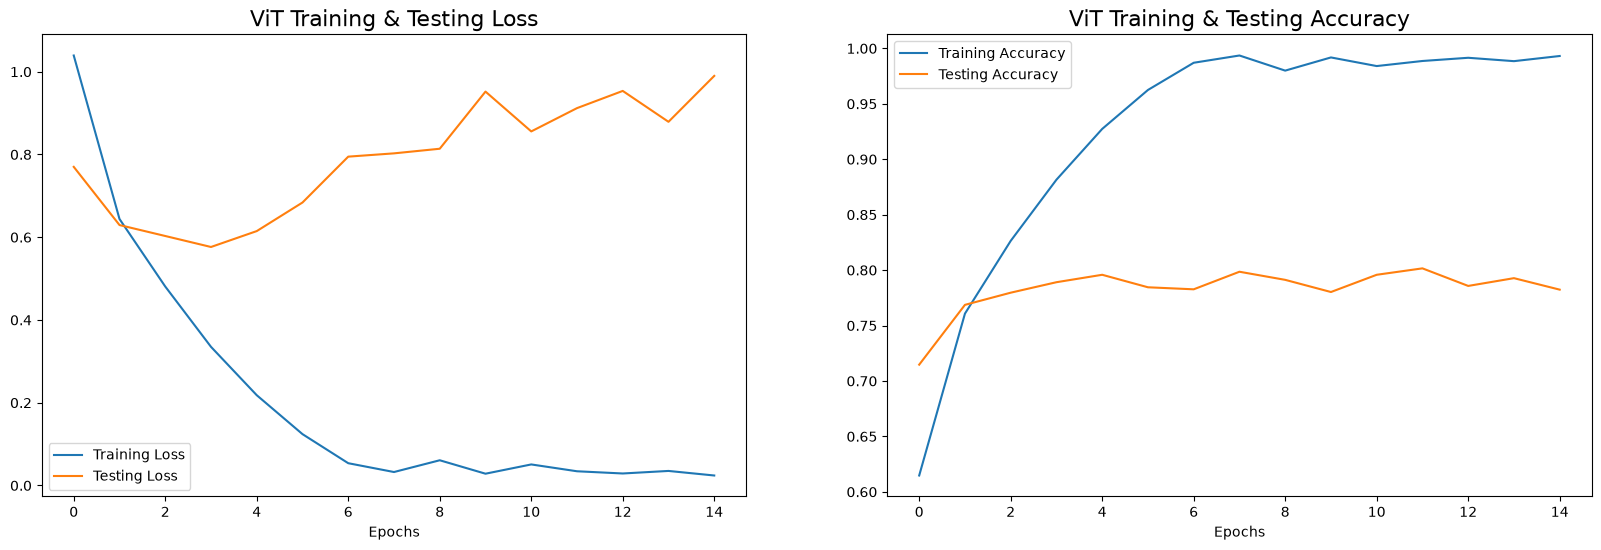

In [ ]:
epochs_range = range(epochs)
fig, ax = plt.subplots(1, 2, figsize=(20, 6))

# Plot Training & Validation Loss
ax[0].plot(epochs_range, history_vit['loss'], label='Training Loss')
ax[0].plot(epochs_range, history_vit['val_loss'], label='Testing Loss')
ax[0].set_title('ViT Training & Testing Loss', size=16)
ax[0].set_xlabel("Epochs")
ax[0].legend()

# Plot Training & Validation Accuracy
ax[1].plot(epochs_range, history_vit['accuracy'], label='Training Accuracy')
ax[1].plot(epochs_range, history_vit['val_accuracy'], label='Testing Accuracy')
ax[1].set_title('ViT Training & Testing Accuracy', size=16)
ax[1].set_xlabel("Epochs")
ax[1].legend()

plt.show()

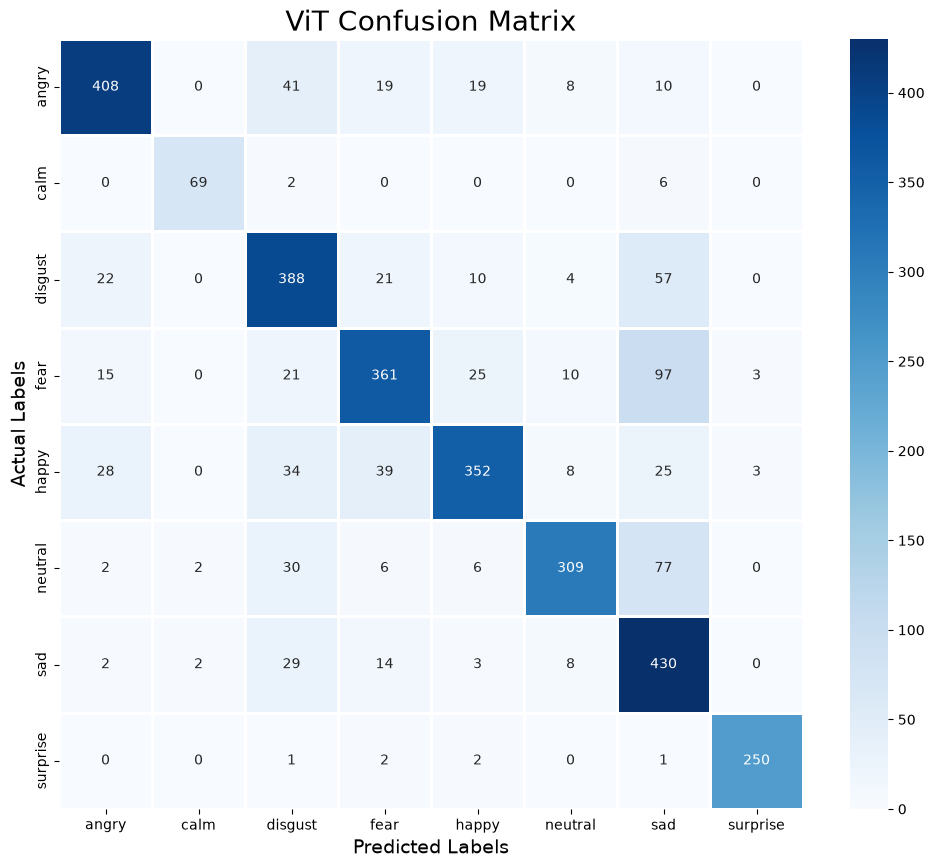

--- Vision Transformer Classification Report ---
              precision    recall  f1-score   support

       angry       0.86      0.81      0.83       505
        calm       0.95      0.90      0.92        77
     disgust       0.71      0.77      0.74       502
        fear       0.78      0.68      0.73       532
       happy       0.84      0.72      0.78       489
     neutral       0.89      0.72      0.79       432
         sad       0.61      0.88      0.72       488
    surprise       0.98      0.98      0.98       256

    accuracy                           0.78      3281
   macro avg       0.83      0.81      0.81      3281
weighted avg       0.80      0.78      0.78      3281



In [ ]:
model_vit.eval()
all_vit_preds = []
all_vit_trues = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        
        # HuggingFace ViT returns a SequenceClassifierOutput; we need .logits
        outputs = model_vit(inputs)
        preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
        
        all_vit_preds.extend(preds)
        all_vit_trues.extend(labels.numpy())

# Map integer indices back to original string emotion labels
categories_vit = encoder_vit.classes_
y_pred_labels_vit = categories_vit[all_vit_preds]
y_test_labels_vit = categories_vit[all_vit_trues]

# Generate the Confusion Matrix
cm_vit = confusion_matrix(y_test_labels_vit, y_pred_labels_vit, labels=categories_vit)

# Plot the Heatmap
plt.figure(figsize=(12, 10))
cm_vit_df = pd.DataFrame(cm_vit, index=categories_vit, columns=categories_vit)

# fmt='d' ensures integer formatting
sns.heatmap(cm_vit_df, linecolor='white', cmap='Blues', linewidth=1, annot=True, fmt='d')
plt.title('ViT Confusion Matrix', size=20)
plt.xlabel('Predicted Labels', size=14)
plt.ylabel('Actual Labels', size=14)
plt.show()

# Print the Classification Report
print("--- Vision Transformer Classification Report ---")
print(classification_report(y_test_labels_vit, y_pred_labels_vit, target_names=categories_vit))

# Part 2: Finding the Data Leakage

The scores above look excellent: Random Forest **86.05%**, 1D CNN **74.39%**, Stacked CNN **82%**, Hierarchical Ensemble **80.98%**, ViT **78%**. They are not real. Three separate problems let the models see the test set during training:

1. **Duplicate files.** The Kaggle archives for RAVDESS and TESS contain a second, nested copy of every recording.
2. **Augmenting before splitting.** Each file became 5 feature rows (original, noise, stretch, shift, pitch) *before* `train_test_split`, so augmented copies of a test clip sat in the training set.
3. **Row-level split.** Splitting rows instead of speakers put the same voices in train and test. A real user of the app is a voice the model has never heard.

The cells below prove each one, then measure how much it inflates accuracy.

In [1]:
# Parts 2 and 3 are self-contained: they do not need the Part 1 cells to be re-run
import os
import sys
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore', message='IProgress not found')

# This notebook lives in notebooks/; add the project root so the src/ package can be imported
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT))
from src import ingestion
from src.config import DATASET_DIR, METADATA_CSV, META_COLUMNS, RESULTS_DIR

# Walk every .wav exactly like the original metadata builder did (no de-duplication)
rows = []
for source in ['ravdess', 'tess', 'cremad', 'savee']:
    for root, dirs, files in os.walk(DATASET_DIR / source):
        dirs.sort()
        for file in sorted(files):
            if file.endswith('.wav'):
                rows.append({'source': source, 'file': file, 'path': os.path.join(root, file),
                             'speaker': ingestion.get_speaker(source, file, root)})
raw = pd.DataFrame(rows)
raw['key'] = raw['source'] + '/' + raw['file']

summary = raw.groupby('source').agg(rows=('key', 'size'), unique_recordings=('key', 'nunique'))
summary['duplicate_rows'] = summary['rows'] - summary['unique_recordings']
summary.loc['total'] = summary.sum()
print(summary.to_string())

          rows  unique_recordings  duplicate_rows
source                                           
cremad    7442               7442               0
ravdess   2880               1440            1440
savee      480                480               0
tess      5600               2800            2800
total    16402              12162            4240


### Leak 1: every RAVDESS and TESS recording appears twice

RAVDESS has 2,880 rows but only 1,440 unique recordings, and TESS has 5,600 rows but 2,800 unique. **4,240 of the 16,402 rows (26%) are duplicates.** The second copy sits in a nested folder inside the Kaggle archive:

In [2]:
# Where the two copies of one recording live
for key in ['ravdess/03-01-05-01-01-01-01.wav', 'tess/OAF_back_angry.wav']:
    print(key)
    for path in raw.loc[raw['key'] == key, 'path']:
        print('   ', Path(path).relative_to(ROOT))

# Are the copies really the same audio? Hash 300 random duplicate pairs byte for byte
def md5(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()

dup_keys = raw.loc[raw.duplicated('key', keep=False), 'key'].drop_duplicates().sample(300, random_state=0)
identical = sum(raw.loc[raw['key'] == k, 'path'].map(md5).nunique() == 1 for k in dup_keys)
print(f"\n{identical} of {len(dup_keys)} sampled duplicate pairs are byte-for-byte identical")

ravdess/03-01-05-01-01-01-01.wav
    data\dataset\ravdess\Actor_01\03-01-05-01-01-01-01.wav
    data\dataset\ravdess\audio_speech_actors_01-24\Actor_01\03-01-05-01-01-01-01.wav
tess/OAF_back_angry.wav
    data\dataset\tess\TESS Toronto emotional speech set data\OAF_angry\OAF_back_angry.wav
    data\dataset\tess\TESS Toronto emotional speech set data\TESS Toronto emotional speech set data\OAF_angry\OAF_back_angry.wav

300 of 300 sampled duplicate pairs are byte-for-byte identical


### Leaks 2 and 3: augmented copies and shared speakers

The original pipeline turned each of the 16,402 rows into 5 feature rows, then split those 82,010 rows randomly 75/25 (61,507 train / 20,503 test, as printed in Part 1). Rebuilding that split shows what each test row had in common with the training set:

In [3]:
# Recreate the original layout: 5 feature rows per file, then a random 75/25 row split
row_key = np.repeat(raw['key'].to_numpy(), 5)
row_speaker = np.repeat(raw['speaker'].to_numpy(), 5)
train_idx, test_idx = train_test_split(np.arange(len(row_key)), test_size=0.25, random_state=0, shuffle=True)
print(f"Train rows: {len(train_idx)}, test rows: {len(test_idx)}")

train_keys, train_speakers = set(row_key[train_idx]), set(row_speaker[train_idx])
same_recording = np.isin(row_key[test_idx], list(train_keys)).mean()
same_speaker = np.isin(row_speaker[test_idx], list(train_speakers)).mean()

print(f"Test rows whose exact recording (another augmented copy or the duplicate file) is in train: {same_recording:.1%}")
print(f"Test rows whose speaker is in train: {same_speaker:.1%}")

Train rows: 61507, test rows: 20503
Test rows whose exact recording (another augmented copy or the duplicate file) is in train: 99.8%
Test rows whose speaker is in train: 100.0%


**Almost every test row had a near-copy of itself in the training set**, and every test speaker was a familiar voice. The models could score well by recognizing recordings they had already seen, not by recognizing emotion.

### How much does the leak inflate accuracy?

A controlled experiment: the same 162 features as Part 1, the same Random Forest, and the same pool of clips (the 7,916 training-split files of the corrected dataset, 5 augmented rows each, 84 speakers). **Only the way the 80/20 split is drawn changes:**

- **Leaky:** random rows, as in Part 1. Augmented copies and voices are shared.
- **Honest:** whole speakers held out with `GroupShuffleSplit`. Unseen voices only.

Pool: 39580 rows, 84 speakers
Leaky (random rows)         81.1%
Honest (unseen speakers)    46.2%


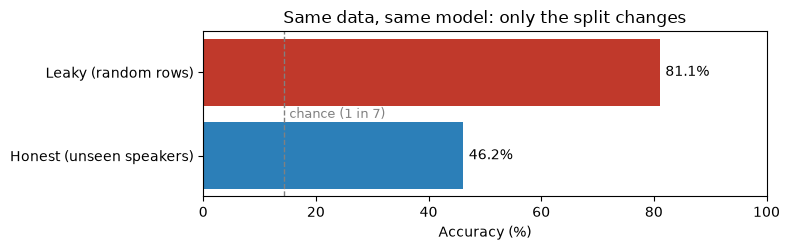

In [4]:
feats_v1 = pd.read_csv(ROOT / 'data' / 'features_v1.csv')
pool = feats_v1[feats_v1['split'] == 'train'].reset_index(drop=True)
X_pool = pool.drop(columns=META_COLUMNS).values
y_pool = pool['labels_emotion'].values
print(f"Pool: {len(pool)} rows, {pool['speaker'].nunique()} speakers")

def rf_accuracy(train_rows, test_rows):
    scaler = StandardScaler().fit(X_pool[train_rows])
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)
    rf.fit(scaler.transform(X_pool[train_rows]), y_pool[train_rows])
    return accuracy_score(y_pool[test_rows], rf.predict(scaler.transform(X_pool[test_rows])))

leaky_train, leaky_test = train_test_split(np.arange(len(pool)), test_size=0.2, random_state=0)
honest_train, honest_test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
                                 .split(X_pool, y_pool, groups=pool['speaker']))

split_results = pd.Series({
    'Leaky (random rows)': rf_accuracy(leaky_train, leaky_test),
    'Honest (unseen speakers)': rf_accuracy(honest_train, honest_test)
})
print(split_results.map('{:.1%}'.format).to_string())

fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(split_results.index, split_results.values * 100, color=['#c0392b', '#2c7fb8'])
ax.bar_label(bars, labels=[f'{v:.1%}' for v in split_results.values], padding=4)
ax.axvline(100 / 7, color='grey', linestyle='--', linewidth=1)
ax.text(100 / 7 + 1, 0.5, 'chance (1 in 7)', color='grey', fontsize=9, va='center')
ax.set_xlim(0, 100)
ax.set_xlabel('Accuracy (%)')
ax.invert_yaxis()
ax.set_title('Same data, same model: only the split changes')
plt.tight_layout()
plt.show()

The model is identical. Only the split is different, yet the leaky split scores **81.1%** and the honest one **46.2%**. Those 35 points are leakage, and they explain why Part 1's numbers collapsed once the split was fixed.

One more problem in Part 1: the **test set was also used for early stopping and for picking the best epoch** (Stacked CNN "Restoring best model weights with Validation Accuracy: 81.90%"), so even without the leaks it was tuned on the data it reported.

# Part 3: The Corrected Pipeline, and Getting Back to 85%

The fixes now live in the project code (`src/ingestion.py`, `src/extraction_1d.py`, `src/training.py`), not in this notebook:

| Problem | Fix |
| --- | --- |
| Duplicate files | Keep the first copy of each `(dataset, filename)`: 16,402 rows to 12,162 recordings |
| Shared speakers | Split by speaker (about 70/15/15) inside each dataset and sex; TESS's second speaker is held out for val/test |
| Augmentation before the split | Augment only the train split; val and test stay one untouched row per recording |
| Tuning on the test set | Separate validation split for early stopping, best weights, features, hyperparameters and ensemble weights; test is scored once |
| `calm` only in RAVDESS (2%) | Merged into `neutral`, giving 7 classes |

Every number below is read from `results/*.json`, written by the training scripts, and measured on **2,126 recordings from 19 speakers no model heard in training**.

In [5]:
import re
import torch

meta = pd.read_csv(METADATA_CSV)
speakers = meta.groupby('split')['speaker'].apply(set)

print(f"Recordings: {len(meta)} | duplicate (dataset, filename) pairs: {meta.duplicated(subset=['source', 'filepath']).sum()}")
print(f"Speakers per split: " + ", ".join(f"{s}={len(speakers[s])}" for s in ['train', 'val', 'test']))
print(f"Speakers shared by train and test: {len(speakers['train'] & speakers['test'])}, "
      f"by train and val: {len(speakers['train'] & speakers['val'])}\n")
print(pd.crosstab(meta['source'], meta['split'], margins=True).to_string())

# Augmentation happens only in train: 5 feature rows per training recording, 1 per val/test recording
rows_per_split = pd.read_csv(ROOT / 'data' / 'features.csv', usecols=['split'])['split'].value_counts()
files_per_split = meta['split'].value_counts()
print("\nFeature rows per recording: " + ", ".join(
    f"{s}={rows_per_split[s] / files_per_split[s]:.0f}" for s in ['train', 'val', 'test']))

Recordings: 12162 | duplicate (dataset, filename) pairs: 0
Speakers per split: train=84, val=19, test=19
Speakers shared by train and test: 0, by train and val: 0

split    test  train   val    All
source                           
cremad   1066   5316  1060   7442
ravdess   240    960   240   1440
savee     120    240   120    480
tess      700   1400   700   2800
All      2126   7916  2120  12162

Feature rows per recording: train=5, val=1, test=1


## The improvement ladder

Fixing the leak dropped the best model from a claimed 86% to an honest **63%**. Each step below was chosen on the **validation** split; the test score is shown for the record.

,val accuracy %,test accuracy %,test macro F1 %
step,,,
1. First honest run (best model: ViT),-,63.3,64.5
"2. Richer features, regularized ViT",65.9,64.8,66.3
3. New model: WavLM-Base+ (2.5 s window),76.7,79.1,80.0
"4. 4 s silence-trimmed window, stable training",80.5,81.8,82.1
5. WavLM-Large (316M parameters),81.2,81.0,79.8
6. Validation-tuned ensemble,85.4,85.2,85.4


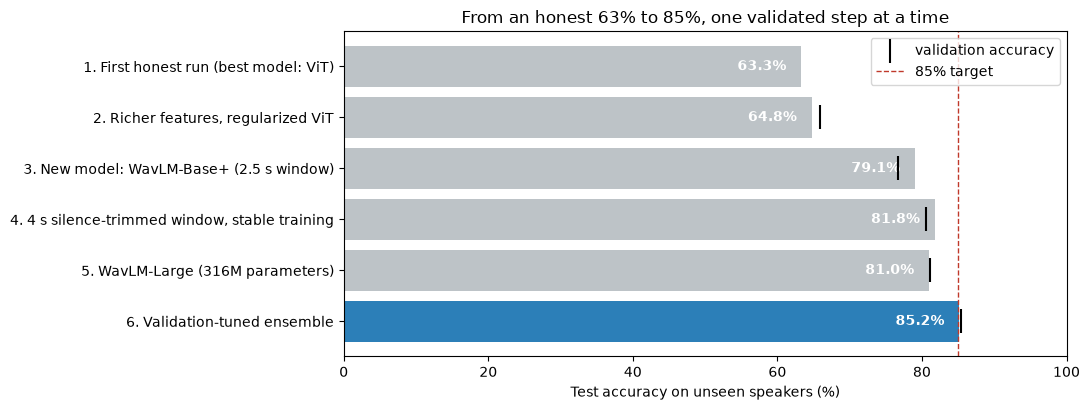

In [6]:
def load_result(name, folder=RESULTS_DIR):
    path = folder / f'{name}.json'
    return json.loads(path.read_text()) if path.exists() else None

# Validation accuracy of each run, recomputed from its saved probabilities (results/<run>_probs.npz)
waves = torch.load(ROOT / 'data' / 'wave_tensors.pt', weights_only=False)
y_val = waves['y'].numpy()[waves['split'] == 'val']
y_test = waves['y'].numpy()[waves['split'] == 'test']
test_sources = waves['source'][waves['split'] == 'test']

def val_accuracy(run):
    path = RESULTS_DIR / f'{run}_probs.npz'
    return accuracy_score(y_val, np.load(path)['val'].argmax(1)) if path.exists() else None

ensemble = load_result('ensemble_best')
# (step, test result, validation accuracy); the first run predates saved probabilities, so it has no val score here
steps = [
    ('1. First honest run (best model: ViT)', load_result('vit', RESULTS_DIR / 'initial_run'), np.nan),
    ('2. Richer features, regularized ViT', load_result('vit'), val_accuracy('vit')),
    ('3. New model: WavLM-Base+ (2.5 s window)', load_result('wavlm'), val_accuracy('wavlm')),
    ('4. 4 s silence-trimmed window, stable training', load_result('wavlm_4s'), val_accuracy('wavlm_4s')),
    ('5. WavLM-Large (316M parameters)', load_result('wavlm_large'), val_accuracy('wavlm_large')),
    ('6. Validation-tuned ensemble', ensemble, ensemble['val_accuracy']),
]
ladder = pd.DataFrame([{
    'step': label,
    'val accuracy %': val * 100,
    'test accuracy %': result['accuracy'] * 100,
    'test macro F1 %': result['macro_f1'] * 100
} for label, result, val in steps]).set_index('step')
display(ladder.round(1).fillna('-'))

fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.barh(ladder.index, ladder['test accuracy %'], color=['#bdc3c7'] * (len(ladder) - 1) + ['#2c7fb8'])
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in ladder['test accuracy %']], padding=-46, color='white', fontweight='bold')
ax.scatter(ladder['val accuracy %'], range(len(ladder)), color='black', marker='|', s=300, zorder=3, label='validation accuracy')
ax.axvline(85, color='#c0392b', linestyle='--', linewidth=1, label='85% target')
ax.set_xlim(0, 100)
ax.set_xlabel('Test accuracy on unseen speakers (%)')
ax.invert_yaxis()
ax.legend(loc='upper right')
ax.set_title('From an honest 63% to 85%, one validated step at a time')
plt.tight_layout()
plt.show()

Step 5 is a good example of choosing on validation: WavLM-Large scored *higher* than step 4 on validation but slightly *lower* on test. Picking by test would have been tuning on the test set. The ensemble (step 6) combines both, so the choice did not matter in the end.

## Step 2: richer hand-crafted features

The original 162 features kept only the **average** of each measurement over the clip, used raw (not log) mel power and had no pitch. The new **v2** set (550 dims) adds the standard deviation over time (how the voice *moves*), log-mel, 40 MFCCs with deltas, spectral shape and pitch percentiles. The choice was made on validation:

In [7]:
comparison = json.loads((RESULTS_DIR / 'feature_comparison.json').read_text())
feature_table = pd.DataFrame({
    learner: {f"{fs} ({comparison[fs]['dimension']} dims)": comparison[fs][learner]['val_accuracy'] * 100 for fs in comparison}
    for learner in ['logistic_regression', 'stacked_cnn', 'random_forest']
}).T
feature_table['Change'] = feature_table.iloc[:, 1] - feature_table.iloc[:, 0]
display(feature_table.round(1))

,v1 (162 dims),v2 (550 dims),Change
logistic_regression,37.2,54.5,17.4
stacked_cnn,46.4,54.1,7.6
random_forest,41.9,43.4,1.5


Even so, the best hand-crafted model stays near 55% on test. The big jump came from a model that learns its own features.

## Steps 3-4: WavLM, and giving it the whole sentence

**WavLM** is a transformer pre-trained by Microsoft on 94k hours of raw speech. Fine-tuned on our clips, it went straight to 79%. It was still only hearing a fixed **2.5 s window starting at 0.6 s**, though, and many recordings are longer than that:

,median_length_s,longest_s,share_cut_off
source,,,
cremad,2.50,5.00,0.13
ravdess,3.67,5.27,0.99
savee,3.67,7.14,0.74
tess,2.05,2.98,0.00


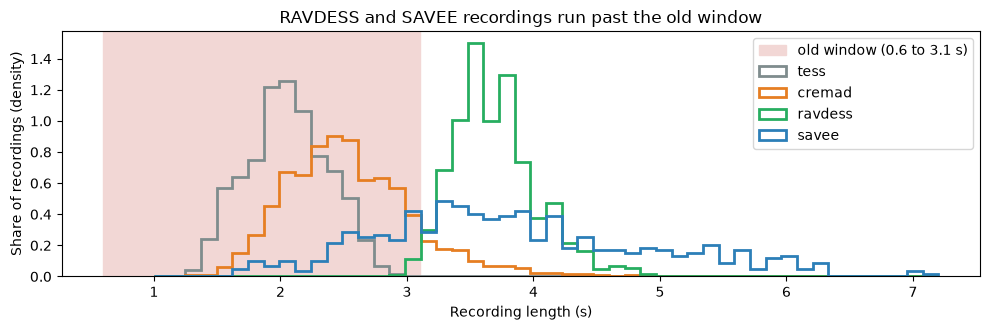

,cremad,ravdess,savee,tess,overall
2.5 s window,72.2,80.8,62.5,91.7,79.1
"4 s, silence-trimmed",75.0,86.2,64.2,93.6,81.8


In [8]:
import soundfile as sf
meta['duration_s'] = [sf.info(str(ROOT / p)).duration for p in meta['filepath']]
cut = meta.assign(cut_by_window=meta['duration_s'] > 3.1).groupby('source').agg(
    median_length_s=('duration_s', 'median'), longest_s=('duration_s', 'max'), share_cut_off=('cut_by_window', 'mean'))
display(cut.round(2))

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axvspan(0.6, 3.1, color='#f2d7d5', zorder=0, label='old window (0.6 to 3.1 s)')
for source, color in zip(['tess', 'cremad', 'ravdess', 'savee'], ['#7f8c8d', '#e67e22', '#27ae60', '#2c7fb8']):
    ax.hist(meta.loc[meta['source'] == source, 'duration_s'], bins=50, range=(1, 7.2), density=True,
            histtype='step', linewidth=2, label=source, color=color)
ax.set_xlabel('Recording length (s)')
ax.set_ylabel('Share of recordings (density)')
ax.legend()
ax.set_title('RAVDESS and SAVEE recordings run past the old window')
plt.tight_layout()
plt.show()

window = pd.DataFrame({'2.5 s window': load_result('wavlm')['per_source_accuracy'],
                       '4 s, silence-trimmed': load_result('wavlm_4s')['per_source_accuracy']}).T * 100
window['overall'] = [load_result('wavlm')['accuracy'] * 100, load_result('wavlm_4s')['accuracy'] * 100]
display(window.round(1))

The new input trims leading and trailing silence and keeps up to 4 s, so each clip is the whole utterance. That lifted WavLM from 79.1% to 81.8%, with the biggest gains on RAVDESS and on the `sad` and `happy` classes.

### A training-stability bug along the way

About half of the WavLM runs **collapsed**: stuck near 40% from the first epoch while healthy runs reach ~65% after one. That included every early WavLM-Large attempt. The fixes were learning-rate warmup, gradient clipping and full fp32 precision (bfloat16 had been used for speed). They reduce collapses but do not eliminate them, so every run's validation score is checked and collapsed runs are never used:

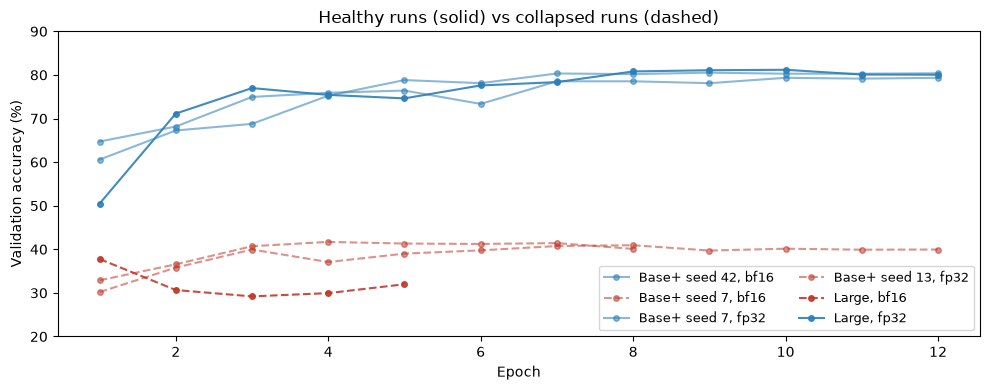

In [9]:
EPOCH = re.compile(r'Epoch \[(\d+)/\d+\] - loss: [\d.]+ - acc: [\d.]+ \| val_loss: [\d.]+ - val_acc: ([\d.]+)')
runs = {
    'Base+ seed 42, bf16': ('wavlm_4s_v2', '-'), 'Base+ seed 7, bf16': ('wavlm_4s_s7', '--'),
    'Base+ seed 7, fp32': ('wavlm_4s_s7_fp32', '-'), 'Base+ seed 13, fp32': ('wavlm_4s_s13_fp32', '--'),
    'Large, bf16': ('wavlm_large_v2', '--'), 'Large, fp32': ('wavlm_large_fp32', '-'),
}
fig, ax = plt.subplots(figsize=(10, 4))
for label, (log, style) in runs.items():
    path = ROOT / 'logs' / f'{log}.log'
    if not path.exists():
        print(f"{path.name} not found (logs/ is not in git); skipping")
        continue
    curve = [(int(e), float(v) * 100) for e, v in EPOCH.findall(path.read_text(errors='ignore'))]
    ax.plot(*zip(*curve), style, marker='o', markersize=4, label=label,
            color='#c0392b' if style == '--' else '#2c7fb8', alpha=0.9 if 'Large' in label else 0.55)
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation accuracy (%)')
ax.set_ylim(20, 90)
ax.legend(ncol=2, fontsize=9)
ax.set_title('Healthy runs (solid) vs collapsed runs (dashed)')
plt.tight_layout()
plt.show()

## Steps 5-6: WavLM-Large and the ensemble

With stable training, **WavLM-Large** became the best single model on validation (81.2%). It is strongest exactly where the others are weakest (CREMA-D and SAVEE).

The final model averages the probabilities of several healthy runs. Members and weights were picked by greedy forward selection on the **validation** split (repeatedly add the model that most improves the running average), then test was scored once:

In [10]:
weights = json.loads((ROOT / 'saved_models' / 'ensemble_best_weights.json').read_text())
member_names = {'wavlm_large': 'WavLM-Large, 4 s', 'vit': 'Vision Transformer', 'wavlm_4s_s7_fp32': 'WavLM-Base+, 4 s, seed 7',
                'wavlm_4s_bal': 'WavLM-Base+, 4 s, balanced', 'wavlm': 'WavLM-Base+, 2.5 s'}
members = pd.DataFrame([{
    'member': member_names.get(run, run), 'weight': weight,
    'val accuracy %': val_accuracy(run) * 100,
    'test accuracy %': accuracy_score(y_test, np.load(RESULTS_DIR / f'{run}_probs.npz')['test'].argmax(1)) * 100
} for run, weight in weights.items()]).sort_values('weight', ascending=False)
members.loc[len(members)] = ['Best Ensemble', 1.0, ensemble['val_accuracy'] * 100, ensemble['accuracy'] * 100]
display(members.set_index('member').round(2))

,weight,val accuracy %,test accuracy %
member,,,
"WavLM-Large, 4 s",0.35,81.18,81.00
Vision Transformer,0.30,65.94,64.72
"WavLM-Base+, 4 s, seed 7",0.20,79.34,79.35
"WavLM-Base+, 4 s, balanced",0.10,76.93,78.36
"WavLM-Base+, 2.5 s",0.05,76.70,79.07
Best Ensemble,1.00,85.38,85.18


The ViT is the weakest member on its own (~66%), yet it gets one of the largest weights. It "listens" to a picture of the spectrogram instead of the waveform, so its mistakes overlap least with the WavLM runs', and that is what an ensemble needs.

## How even is it?

The ensemble reaches **85.2%** overall, but not evenly. Recall per dataset and emotion:

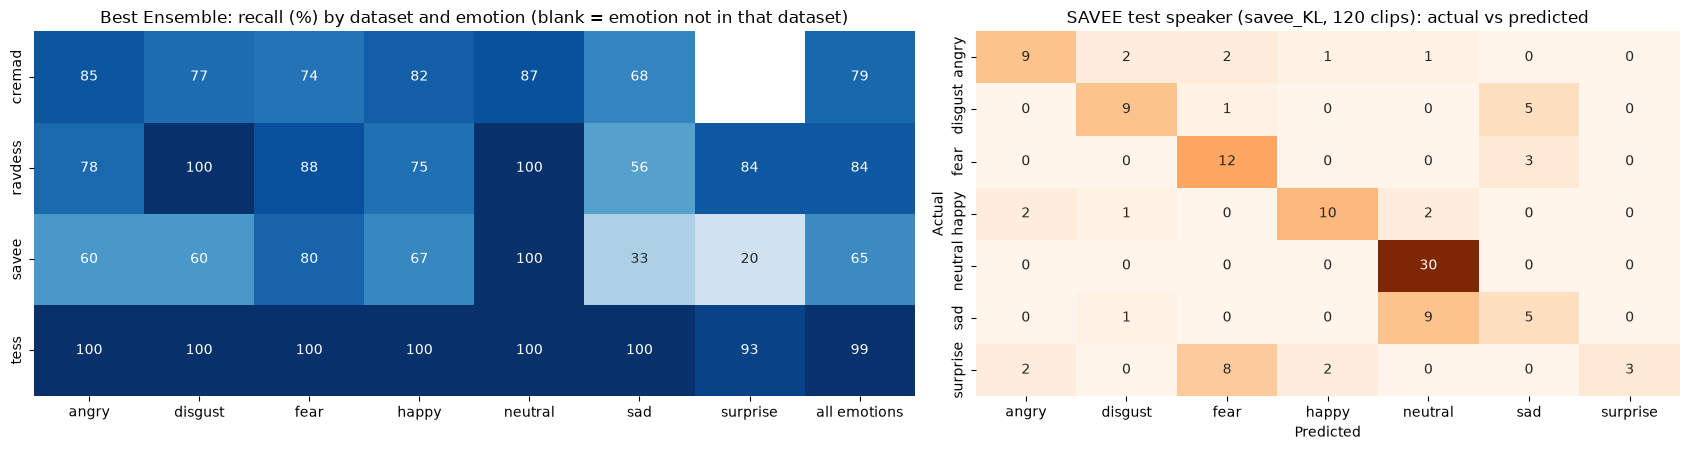

In [11]:
classes = np.array(sorted(ensemble['class_names']))
fused = sum(w * np.load(RESULTS_DIR / f'{run}_probs.npz')['test'] for run, w in weights.items())
test_meta = meta[meta['split'] == 'test'].reset_index(drop=True).assign(pred=classes[fused.argmax(1)])
test_meta['correct'] = test_meta['emotion'] == test_meta['pred']

recall = test_meta.pivot_table(index='source', columns='emotion', values='correct', aggfunc='mean') * 100
recall['all emotions'] = test_meta.groupby('source')['correct'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(recall, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, ax=axes[0], cbar=False)
axes[0].set_title('Best Ensemble: recall (%) by dataset and emotion (blank = emotion not in that dataset)')
axes[0].set_xlabel('')
axes[0].set_ylabel('')

savee = test_meta[test_meta['source'] == 'savee']
sns.heatmap(pd.crosstab(savee['emotion'], savee['pred']), annot=True, fmt='d', cmap='Oranges', ax=axes[1], cbar=False)
axes[1].set_title(f"SAVEE test speaker ({savee['speaker'].iloc[0]}, {len(savee)} clips): actual vs predicted")
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()

- **TESS is nearly solved** (99%): two speakers reading single words.
- **`sad` is the hardest emotion everywhere**, often heard as `neutral`.
- **SAVEE (65%) is one male speaker**, 120 clips, so each clip is worth 0.8 points. His surprise is mostly heard as fear and his sadness as neutral. Only two SAVEE speakers are available for training, so more male speakers would help this more than more tuning.

## Live check: the Best Ensemble on unseen speakers

The saved ensemble runs through the same code path as the Streamlit app (`app/inference.py`), on full-length recordings:

In [12]:
import io
import logging
from app.inference import load_artifacts, load_selected_model, load_audio, run_inference
from src.config import to_project_path
# Streamlit warns that it is not running inside an app; harmless here
logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context').setLevel(logging.ERROR)

scaler, encoder, sex_encoder = load_artifacts()
best_model = load_selected_model('Best Ensemble', len(encoder.classes_), scaler.n_features_in_)

demo = meta[meta['split'] == 'test'].groupby('source').sample(3, random_state=1)
predictions = []
for _, row in demo.iterrows():
    audio = load_audio(io.BytesIO(to_project_path(row['filepath']).read_bytes()))
    emotion, probs, _ = run_inference(audio, 'Best Ensemble', best_model, scaler, encoder, sex_encoder)
    predictions.append({'dataset': row['source'], 'speaker': row['speaker'], 'true': row['emotion'],
                        'predicted': emotion, 'confidence': f'{probs.max():.0%}',
                        'correct': 'yes' if emotion == row['emotion'] else 'no'})
display(pd.DataFrame(predictions))

,dataset,speaker,true,predicted,confidence,correct
0,cremad,cremad_1011,sad,sad,80%,yes
1,cremad,cremad_1034,fear,angry,52%,no
2,cremad,cremad_1069,angry,angry,92%,yes
3,ravdess,ravdess_18,neutral,neutral,79%,yes
4,ravdess,ravdess_05,surprise,surprise,52%,yes
5,ravdess,ravdess_05,neutral,neutral,88%,yes
6,savee,savee_KL,happy,happy,34%,yes
7,savee,savee_KL,surprise,happy,27%,no
8,savee,savee_KL,neutral,neutral,74%,yes
9,tess,tess_YAF,happy,happy,63%,yes


## Takeaways

- The original 74–86% scores came from **leakage**: duplicate files, augmented copies of test clips in train, and familiar voices in test. With the same features and model, an honest speaker split drops the score from 81% to 46%.
- After the fixes, the honest baseline was **63%** at best. Richer features helped the hand-crafted models, but the big gains came from **WavLM** (pre-trained on raw speech), **whole-utterance input** and **stable fine-tuning**.
- A **validation-tuned ensemble** reaches **85.2% test accuracy (85.4% macro F1)** on speakers no model had heard. It is the model the app opens on.
- It is not yet even across datasets: TESS 99%, RAVDESS 84%, CREMA-D 79%, **SAVEE 65%**. The weakest spots (SAVEE, `sad`) look like data limits more than modeling limits.